# Segmentação em duas etapas SSD + FCN

Esta proposta busca enfrentar o desafio da detecção e segmentação de cicatrizes de queima em imagens de sensoriamento remoto, adotando uma estratégia em duas etapas que combina rapidez de detecção com precisão na segmentação de contornos.

Na primeira etapa, utilizamos a arquitetura SSD (Single Shot MultiBox Detector) [Liu et al., 2016], uma rede neural convolucional projetada para detecção de objetos em tempo real. O SSD realiza a previsão de bounding boxes em múltiplas escalas e com diferentes razões de aspecto, oferecendo um equilíbrio robusto entre desempenho computacional e acurácia. 

Na segunda etapa, os bounding boxes produzidos pelo SSD são processados por uma rede de Fully Convolutional Networks (FCN) [Long et al., 2015], arquitetura que inaugurou a segmentação semântica baseada em convoluções puramente espaciais. Nossa proposta adapta a FCN para lidar com imagens bidimensionais de canal único, correspondentes ao índice NBRSWIR (Normalized Burn Ratio Short-Wave Infrared). Esse índice, construído a partir de bandas do infravermelho de onda curta, é amplamente utilizado na detecção de áreas queimadas e cicatrizes em ambientes de monitoramento terrestre. Inspiramo-nos em abordagens recentes de segmentação para detecção de lesões médicas em imagens monocanal [Zheng et al., 2025], transpondo essa estratégia para o contexto de sensoriamento remoto.

O objetivo é unir as vantagens do SSD — rapidez e detecção em múltiplas escalas — com a precisão espacial da FCN — máscaras detalhadas de cicatrizes —, resultando em um pipeline de processamento modular, eficiente e escalável. O método visa fornecer resultados que possam ser integrados a fluxos operacionais de monitoramento ambiental, auxiliando no mapeamento rápido e preciso de cicatrizes de queima, com impacto direto em gestão ambiental, monitoramento climático e suporte à tomada de decisão em desastres naturais.

Referências principais

SSD: Liu, W. et al. (2016). SSD: Single Shot MultiBox Detector. In European Conference on Computer Vision (ECCV), pp. 21–37.

FCN: Long, J., Shelhamer, E., & Darrell, T. (2015). Fully Convolutional Networks for Semantic Segmentation. In IEEE Conference on Computer Vision and Pattern Recognition (CVPR), pp. 3431–3440.

Índice NBRSWIR: Key, C.H., & Benson, N.C. (2006). Landscape assessment (LA): Sampling and analysis methods. In Firemon: Fire effects monitoring and inventory system. USDA Forest Service.

Aplicações recentes (inspiração médica): Zheng, X. et al. (2025). Medical ImageCAS Dataset. Kaggle. Disponível em: https://www.kaggle.com/datasets/xiaoweixumedicalai/imagecas. 



Equipe:
- Murilo Patricio Maia: murilo.maiia@outlook.com
- Alice Martins Valero: alicia.mar.val@gmail.com


---
# Instalando e Importando Pacotes

In [1]:
#Instalações
!pip install opencv-python
!pip install rasterio
!pip install tqdm
!pip install spyndex xarray
!pip install albumentations
!pip install torch
!pip install torchvision
!pip install scikit-learn

  Using cached opencv_python-4.12.0.88-cp37-abi3-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (67.0 MB)
  Using cached numpy-2.2.6-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.8 MB)
  Using cached rasterio-1.4.3-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (22.2 MB)
  Using cached attrs-25.3.0-py3-none-any.whl (63 kB)
  Using cached click_plugins-1.1.1.2-py2.py3-none-any.whl (11 kB)
  Using cached pyparsing-3.2.3-py3-none-any.whl (111 kB)
  Using cached cligj-0.7.2-py3-none-any.whl (7.1 kB)
  Using cached click-8.2.1-py3-none-any.whl (102 kB)
  Using cached affine-2.4.0-py3-none-any.whl (15 kB)
  Using cached certifi-2025.8.3-py3-none-any.whl (161 kB)
  Using cached tqdm-4.67.1-py3-none-any.whl (78 kB)
  Using cached spyndex-0.7.1-py3-none-any.whl (769 kB)
  Using cached xarray-2025.6.1-py3-none-any.whl (1.3 MB)
  Using cached dask-2025.7.0-py3-none-any.whl (1.5 MB)
  Using cached pyarrow-21.0.0-cp310-cp310-manylinux_2_28_x86_64.whl (42.7 MB)
  Using c

In [2]:
#Importações
import cv2
import os
import xml.etree.ElementTree as ET
from tqdm import tqdm
import numpy as np
import rasterio
import spyndex
import matplotlib.pyplot as plt
import random
import json
import torch
import torchvision.transforms.functional as FT
from torch import nn
import torch.nn.functional as F
from math import sqrt
from itertools import product as product
import torchvision
from PIL import Image
from torch.utils.data import Dataset
import time
import torch.backends.cudnn as cudnn
import torch.optim
import torch.utils.data
from torchvision import transforms
from PIL import Image, ImageDraw, ImageFont
from pprint import PrettyPrinter
from rasterio.transform import from_origin
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
import pandas as pd
import pickle
from sklearn.metrics import roc_auc_score, roc_curve
import math
import csv

---
# SSD

## Funções auxiliares

### Parâmetros e Variáveis

In [3]:
#Variáveis e Parâmetros

#Lista de "objetos"
voc_labels = ('burn_scar',)

# Parâmetros de treino
batch_size = 16  # batch size
iterations = 120000  # number of iterations to train
workers = 4  # number of workers for loading data in the DataLoader
print_freq = 200  # print training status every __ batches
lr = 1e-3  # learning rate
decay_lr_at = [80000, 100000]  # decay learning rate after these many iterations
decay_lr_to = 0.1  # decay learning rate to this fraction of the existing learning rate
momentum = 0.9  # momentum
weight_decay = 5e-4  # weight decay
grad_clip = None  # clip if gradients are exploding, which may happen at larger batch sizes (sometimes at 32) - you will recognize it by a sorting error in the MuliBox loss calculation



label_map = {k: v + 1 for v, k in enumerate(voc_labels)}
label_map['background'] = 0
rev_label_map = {v: k for k, v in label_map.items()}  # Inverse mapping

distinct_colors = ['#e6194b', '#3cb44b', '#ffe119', '#0082c8', '#f58231', '#911eb4', '#46f0f0', '#f032e6',
                   '#d2f53c', '#fabebe', '#008080', '#000080', '#aa6e28', '#fffac8', '#800000', '#aaffc3', '#808000',
                   '#ffd8b1', '#e6beff', '#808080', '#FFFFFF']
label_color_map = {k: distinct_colors[i] for i, k in enumerate(label_map.keys())}
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
n_classes = len(label_map)  # number of different types of objects
keep_difficult = True  # use objects considered difficult to detect?
cudnn.benchmark = True

### Para criação e preparação de um dataset que o SSD espera receber

In [4]:
def create_voc_xml(image_filename, boxes, image_size, output_folder):
    """
    Gera e salva um arquivo de anotação no formato XML Pascal VOC.

    A função constrói uma estrutura XML padrão contendo metadados da imagem
    e as coordenadas de cada caixa delimitadora fornecida.

    :param image_filename: (str) O nome do arquivo da imagem original (ex: 'recorte_1.jpg').
    :param boxes: (list) Uma lista de listas, onde cada sublista contém as
                  coordenadas de uma caixa delimitadora no formato [xmin, ymin, xmax, ymax].
    :param image_size: (tuple) Uma tupla contendo as dimensões da imagem (altura, largura).
    :param output_folder: (str) O caminho para a pasta onde o arquivo .xml será salvo.
    :return: None
    """
    annotation = ET.Element('annotation')
    ET.SubElement(annotation, 'folder').text = 'Annotations'
    ET.SubElement(annotation, 'filename').text = image_filename
    
    source = ET.SubElement(annotation, 'source')
    ET.SubElement(source, 'database').text = 'Unknown'

    size = ET.SubElement(annotation, 'size')
    ET.SubElement(size, 'width').text = str(image_size[1])
    ET.SubElement(size, 'height').text = str(image_size[0])
    ET.SubElement(size, 'depth').text = '3'

    ET.SubElement(annotation, 'segmented').text = '0'

    for box in boxes:
        xmin, ymin, xmax, ymax = box
        obj = ET.SubElement(annotation, 'object')
        ET.SubElement(obj, 'name').text = 'burn_scar'
        ET.SubElement(obj, 'pose').text = 'Unspecified'
        ET.SubElement(obj, 'truncated').text = '0'
        ET.SubElement(obj, 'difficult').text = '0'
        
        bndbox = ET.SubElement(obj, 'bndbox')
        ET.SubElement(bndbox, 'xmin').text = str(xmin)
        ET.SubElement(bndbox, 'ymin').text = str(ymin)
        ET.SubElement(bndbox, 'xmax').text = str(xmax)
        ET.SubElement(bndbox, 'ymax').text = str(ymax)

    tree = ET.ElementTree(annotation)
    xml_filename = os.path.splitext(image_filename)[0] + '.xml'
    tree.write(os.path.join(output_folder, xml_filename))

def mask_to_boxes_rasterio(mask_path, min_width=0, min_height=0):
    """
    Lê um arquivo de máscara de segmentação (.tif) e extrai as coordenadas
    das caixas delimitadoras (bounding boxes) que envolvem as áreas marcadas.

    :param mask_path: (str) O caminho para o arquivo de máscara .tif.
    :param min_width: (int, opcional) A largura mínima que uma bbox deve ter para ser considerada. Padrão: 0.
    :param min_height: (int, opcional) A altura mínima que uma bbox deve ter para ser considerada. Padrão: 0.
    :return: (tuple) Uma tupla contendo:
             - boxes (list): Uma lista de listas com as coordenadas [xmin, ymin, xmax, ymax]
               de cada caixa encontrada.
             - mask_data.shape (tuple): As dimensões (altura, largura) da imagem de máscara.
    """
    with rasterio.open(mask_path) as src:
        mask_data = src.read(1).astype(np.uint8) 

    contours, _ = cv2.findContours(mask_data, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    boxes = []
    for contour in contours:
        x, y, w, h = cv2.boundingRect(contour)
        if w >= min_width and h >= min_height:
            boxes.append([x, y, x + w, y + h])
        
    return boxes, mask_data.shape

def create_dataset_SSD(base_input_folder, output_dataset_folder, min_box_width=0, min_box_height=0):
    """
    Orquestra o processo de criação de anotações XML para um dataset.

    A função itera sobre todos os arquivos de máscara em uma pasta, extrai as
    caixas delimitadoras de cada uma e chama a função para criar o arquivo XML
    correspondente na pasta de saída.

    :param base_input_folder: (str) Caminho para a pasta raiz que contém a subpasta 'mask'.
    :param output_dataset_folder: (str) Caminho para a pasta de saída do dataset,
                                  onde a subpasta 'Annotations' será criada.
    :param min_box_width: (int, opcional) Largura mínima da bbox a ser mantida.
    :param min_box_height: (int, opcional) Altura mínima da bbox a ser mantida.                              
    :return: None
    """
    mask_folder = os.path.join(base_input_folder, 'mask')
    annotations_folder = os.path.join(output_dataset_folder, 'Annotations')

    os.makedirs(annotations_folder, exist_ok=True)

    print("Iniciando a preparação do dataset...")
    if min_box_width > 0 or min_box_height > 0:
        print(f"--> Caixas menores que {min_box_width}x{min_box_height} pixels serão ignoradas.")

    for mask_filename in tqdm(os.listdir(mask_folder)):
        if not mask_filename.endswith('.tif'):
            continue
        
        basename = os.path.splitext(mask_filename)[0] 
        mask_path = os.path.join(mask_folder, mask_filename)
    
        try:
            boxes, image_shape = mask_to_boxes_rasterio(mask_path, min_width=min_box_width, 
                                                        min_height=min_box_height)
            create_voc_xml(basename, boxes, image_shape, annotations_folder)
        except Exception as e:
            print(f"Erro ao processar o arquivo {basename}: {e}")

    print(f"\nProcesso concluído! Dataset gerado em: {output_dataset_folder}")

def has_objects(xml_path):
    """
    Verifica se um arquivo de anotação XML contém pelo menos uma tag <object>.

    :param xml_path: (str) O caminho para o arquivo .xml.
    :return: (bool) True se o arquivo contém um ou mais objetos, False caso contrário.
    """
    try:
        tree = ET.parse(xml_path)
        root = tree.getroot()
        return len(root.findall('object')) > 0
    except (ET.ParseError, FileNotFoundError):
        return False

def split_train_test(dataset_folter, test_split_ratio=0.10):
    """
    Divide o dataset em conjuntos de treino e teste e salva as listas em arquivos .txt.

    A função primeiro classifica todas as amostras em positivas (com objetos) e
    negativas (sem objetos). Em seguida, ela divide apenas as amostras positivas
    na proporção definida, ignorando as negativas, e escreve os nomes dos arquivos
    nos arquivos 'trainval.txt' e 'test.txt'.

    :param dataset_folter: (str) Caminho para a pasta raiz do dataset, que contém a
                           subpasta 'Annotations'.
    :param test_split_ratio: (float, opcional) A proporção do dataset a ser
                             usada para o teste (padrão: 0.10, ou 10%).
    :return: None
    """
    output_folter = os.path.join(dataset_folter, 'ImageSets', 'Main')
    annotations_folter = os.path.join(dataset_folter, 'Annotations')
    print("Iniciando a criação dos conjuntos de treino e teste...")

    os.makedirs(output_folter, exist_ok=True)

    all_basenames = [os.path.splitext(f)[0] for f in os.listdir(annotations_folter) if f.endswith('.xml')]

    positive_samples = []
    negative_samples = []

    print("Classificando amostras em positivas e negativas...")
    for basename in all_basenames:
        xml_path = os.path.join(annotations_folter, basename + '.xml')
        if has_objects(xml_path):
            positive_samples.append(basename)
        else:
            negative_samples.append(basename)

    print(f"Total de amostras encontradas: {len(all_basenames)}")
    print(f"  - Amostras com queimadas (Positivas): {len(positive_samples)}")
    print(f"  - Amostras sem queimadas (Negativas): {len(negative_samples)}")
    print("\nIGNORANDO amostras negativas e usando apenas as positivas para treino e teste.")

    random.shuffle(positive_samples)
    
    total_positive_size = len(positive_samples)
    test_size = int(total_positive_size * test_split_ratio)
    
    test_set = positive_samples[:test_size]
    train_set = positive_samples[test_size:]

    print("\n--- Resultado Final (Apenas Amostras Positivas) ---")
    print(f"Total de amostras de TREINO: {len(train_set)}")
    print(f"Total de amostras de TESTE: {len(test_set)}")
    
    try:
        with open(os.path.join(output_folter, 'trainval.txt'), 'w') as f:
            for item in train_set:
                f.write(f"{item}\n")

        with open(os.path.join(output_folter, 'test.txt'), 'w') as f:
            for item in test_set:
                f.write(f"{item}\n")
        
        print(f"\nArquivos 'trainval.txt' e 'test.txt' criados com sucesso em '{output_folter}'")
    except IOError as e:
        print(f"\nERRO ao escrever os arquivos: {e}")

### Para visualizar o resultado das Bounding Boxs, geradas a partir da máscara

In [5]:
def parse_xml_for_boxes(xml_path):
    """
    Lê um arquivo de anotação no formato XML Pascal VOC e extrai as
    coordenadas de todas as caixas delimitadoras (bounding boxes).

    :param xml_path: (str) O caminho para o arquivo de anotação .xml.
    :return: (list) Uma lista de tuplas, onde cada tupla contém as
             coordenadas de uma caixa no formato (xmin, ymin, xmax, ymax).
             Retorna uma lista vazia se o arquivo não for encontrado ou não
             contiver objetos.
    """
    if not os.path.exists(xml_path):
        print(f"Aviso: Arquivo de anotação não encontrado em {xml_path}")
        return []
    tree = ET.parse(xml_path)
    root = tree.getroot()
    boxes = []
    for obj in root.findall('object'):
        bndbox = obj.find('bndbox')
        xmin = int(bndbox.find('xmin').text)
        ymin = int(bndbox.find('ymin').text)
        xmax = int(bndbox.find('xmax').text)
        ymax = int(bndbox.find('ymax').text)
        boxes.append((xmin, ymin, xmax, ymax))
    return boxes

def view_result(sample_name, original_folder, ssd_folder):
    """
    Gera uma imagem de entrada a partir dos TIFs originais e a visualiza
    junto com a máscara e as caixas delimitadoras de referência (ground-truth).

    A função reconstrói a imagem de entrada (dNBRSWIR )
    e a exibe em três painéis: a imagem gerada, a imagem com as caixas
    de referência e a máscara original com as mesmas caixas.

    :param sample_name: (str) O nome base da amostra a ser visualizada (ex: 'recorte_1').
    :param original_folder: (str) O caminho para a pasta que contém as subpastas 't1', 't2' e 'mask'.
    :param ssd_folder: (str) O caminho para a pasta do dataset processado que contém a subpasta 'Annotations'
    :return: None
    """
    t1_path = os.path.join(original_folder, 't1', sample_name + '.tif')
    t2_path = os.path.join(original_folder, 't2', sample_name + '.tif')
    mask_path = os.path.join(original_folder, 'mask', sample_name + '.tif')
    xml_path = os.path.join(ssd_folder, 'Annotations',sample_name + '.xml')

    if not all(os.path.exists(p) for p in [t1_path, t2_path, mask_path]):
        print(f"Erro: Não foi possível encontrar um dos arquivos .tif para a amostra '{sample_name}'. Verifique os caminhos.")
        return

    with rasterio.open(t1_path) as src_t1:
        t1_band3 = src_t1.read(3).astype(np.float32)
        t1_band4 = src_t1.read(4).astype(np.float32)
    with rasterio.open(t2_path) as src_t2:
        t2_band3 = src_t2.read(3).astype(np.float32)
        t2_band4 = src_t2.read(4).astype(np.float32)

    idx1 = spyndex.computeIndex(index=["NBRSWIR"], params={"S1": t1_band3, "S2": t1_band4})
    idx2 = spyndex.computeIndex(index=["NBRSWIR"], params={"S1": t2_band3, "S2": t2_band4})
    diff_image = idx1 - idx2
   

    normalized_diff = cv2.normalize(diff_image, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_8U)
    generated_image_rgb = cv2.cvtColor(normalized_diff, cv2.COLOR_GRAY2RGB)
    
    bounding_boxes = parse_xml_for_boxes(xml_path)
    if not bounding_boxes:
        print(f"Nenhuma bounding box encontrada para a amostra '{sample_name}'.")

    image_with_boxes = generated_image_rgb.copy()

    with rasterio.open(mask_path) as src:
        mask_data = src.read(1)
    mask_normalized = cv2.normalize(mask_data, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_8U)
    mask_rgb = cv2.cvtColor(mask_normalized, cv2.COLOR_GRAY2RGB)
    mask_with_boxes = mask_rgb.copy()

    for (xmin, ymin, xmax, ymax) in bounding_boxes:
        cv2.rectangle(image_with_boxes, (xmin, ymin), (xmax, ymax), color=(0, 255, 0), thickness=1) 
        cv2.rectangle(mask_with_boxes, (xmin, ymin), (xmax, ymax), color=(255, 0, 0), thickness=1) 

    plt.figure(figsize=(20, 7))

    plt.subplot(1, 3, 1)
    plt.imshow(generated_image_rgb)
    plt.title(f'1. Imagem de Entrada Gerada\n({sample_name})')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(image_with_boxes)
    plt.title(f'2. Imagem com BBoxes\n(Cor: Verde)')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(mask_with_boxes)
    plt.title(f'3. Máscara Original com BBoxes\n(Cor: Vermelho)')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

### Funções principais do SSD

In [6]:
#utils

def calculate_mean_std_on_the_fly(data_folder, original_dir):
    """
    Calcula a média e o desvio padrão gerando as imagens de entrada em tempo real
    a partir dos arquivos .tif originais, replicando a lógica do Dataset.
    """
    
    
    train_images_json_path = os.path.join(data_folder, 'TRAIN_images.json')
    with open(train_images_json_path, 'r') as j:
        
        train_image_paths = json.load(j)

    
    channel_sum = np.zeros(3)
    channel_sum_sq = np.zeros(3)
    pixel_count = 0
    
    print(f"Calculando média e desvio padrão para {len(train_image_paths)} imagens de treino...")
    
    for ref_path in tqdm(train_image_paths):
        
        basename = os.path.basename(ref_path)
        
        
        t1_path = os.path.join(original_dir, 't1', basename)
        t2_path = os.path.join(original_dir, 't2', basename)

        
        with rasterio.open(t1_path) as src_t1:
            t1_band3 = src_t1.read(3).astype(np.float32)
            t1_band4 = src_t1.read(4).astype(np.float32)
        with rasterio.open(t2_path) as src_t2:
            t2_band3 = src_t2.read(3).astype(np.float32)
            t2_band4 = src_t2.read(4).astype(np.float32)

        idx1 = spyndex.computeIndex(index=["NBRSWIR"], params={"S1": t1_band3, "S2": t1_band4})
        idx2 = spyndex.computeIndex(index=["NBRSWIR"], params={"S1": t2_band3, "S2": t2_band4})
        
        diff_image = idx1 - idx2
    
        min_val = diff_image.min()
        max_val = diff_image.max()
        if max_val - min_val > 0:
            normalized_float_image = (diff_image - min_val) / (max_val - min_val)
        else:
            normalized_float_image = np.zeros_like(diff_image)

        pixel_sum = np.sum(normalized_float_image)
        pixel_sum_sq = np.sum(np.square(normalized_float_image))

        channel_sum += [pixel_sum, pixel_sum, pixel_sum]
        channel_sum_sq += [pixel_sum_sq, pixel_sum_sq, pixel_sum_sq]
        pixel_count += normalized_float_image.size
        
    mean = channel_sum / pixel_count
    
    std = np.sqrt((channel_sum_sq / pixel_count) - np.square(mean))
    
    return mean, std

def parse_annotation(annotation_path):
    tree = ET.parse(annotation_path)
    root = tree.getroot()

    boxes = list()
    labels = list()
    difficulties = list()
    for object in root.iter('object'):

        difficult = int(object.find('difficult').text == '1')

        label = object.find('name').text.lower().strip()
        if label not in label_map:
            continue

        bbox = object.find('bndbox')
        xmin = int(bbox.find('xmin').text) - 1
        ymin = int(bbox.find('ymin').text) - 1
        xmax = int(bbox.find('xmax').text) - 1
        ymax = int(bbox.find('ymax').text) - 1

        boxes.append([xmin, ymin, xmax, ymax])
        labels.append(label_map[label])
        difficulties.append(difficult)

    return {'boxes': boxes, 'labels': labels, 'difficulties': difficulties}


def create_data_lists(input_path, output_path):
    """
    Create lists of images, the bounding boxes and labels of the objects in these images, and save these to file.

    """
    input_path = os.path.abspath(input_path)
    output_path = os.path.abspath(output_path)

    train_images = list()
    train_objects = list()
    n_objects = 0

    # Training data
    # Find IDs of images in training data
    with open(os.path.join(output_path, 'ImageSets/Main/trainval.txt')) as f:
        ids = f.read().splitlines()

    for id in ids:
        # Parse annotation's XML file
        objects = parse_annotation(os.path.join(output_path, 'Annotations', id + '.xml'))
        n_objects += len(objects)
        train_objects.append(objects)

        train_images.append(os.path.join(input_path, 't1', id + '.tif'))

    assert len(train_objects) == len(train_images)

    # Save to file
    with open(os.path.join(output_path, 'TRAIN_images.json'), 'w') as j:
        json.dump(train_images, j)
    with open(os.path.join(output_path, 'TRAIN_objects.json'), 'w') as j:
        json.dump(train_objects, j)
    with open(os.path.join(output_path, 'label_map.json'), 'w') as j:
        json.dump(label_map, j)  # save label map too

    print('\nThere are %d training images containing a total of %d objects. Files have been saved to %s.' % (
        len(train_images), n_objects, os.path.abspath(output_path)))

    # Test data
    test_images = list()
    test_objects = list()
    n_objects = 0

    # Find IDs of images in the test data
    with open(os.path.join(output_path, 'ImageSets/Main/test.txt')) as f:
        ids = f.read().splitlines()

    for id in ids:
        # Parse annotation's XML file
        objects = parse_annotation(os.path.join(output_path, 'Annotations', id + '.xml'))
        test_objects.append(objects)
        n_objects += len(objects)
        test_images.append(os.path.join(input_path, 't1', id + '.tif'))

    assert len(test_objects) == len(test_images)

    # Save to file
    with open(os.path.join(output_path, 'TEST_images.json'), 'w') as j:
        json.dump(test_images, j)
    with open(os.path.join(output_path, 'TEST_objects.json'), 'w') as j:
        json.dump(test_objects, j)

    print('\nThere are %d test images containing a total of %d objects. Files have been saved to %s.' % (
        len(test_images), n_objects, os.path.abspath(input_path)))


def decimate(tensor, m):
    """
    Decimate a tensor by a factor 'm', i.e. downsample by keeping every 'm'th value.

    This is used when we convert FC layers to equivalent Convolutional layers, BUT of a smaller size.

    :param tensor: tensor to be decimated
    :param m: list of decimation factors for each dimension of the tensor; None if not to be decimated along a dimension
    :return: decimated tensor
    """
    assert tensor.dim() == len(m)
    for d in range(tensor.dim()):
        if m[d] is not None:
            tensor = tensor.index_select(dim=d,
                                         index=torch.arange(start=0, end=tensor.size(d), step=m[d]).long())

    return tensor


def calculate_mAP(det_boxes, det_labels, det_scores, true_boxes, true_labels, true_difficulties):
    """
    Calculate the Mean Average Precision (mAP) of detected objects.

    See https://medium.com/@jonathan_hui/map-mean-average-precision-for-object-detection-45c121a31173 for an explanation

    :param det_boxes: list of tensors, one tensor for each image containing detected objects' bounding boxes
    :param det_labels: list of tensors, one tensor for each image containing detected objects' labels
    :param det_scores: list of tensors, one tensor for each image containing detected objects' labels' scores
    :param true_boxes: list of tensors, one tensor for each image containing actual objects' bounding boxes
    :param true_labels: list of tensors, one tensor for each image containing actual objects' labels
    :param true_difficulties: list of tensors, one tensor for each image containing actual objects' difficulty (0 or 1)
    :return: list of average precisions for all classes, mean average precision (mAP)
    """
    assert len(det_boxes) == len(det_labels) == len(det_scores) == len(true_boxes) == len(
        true_labels) == len(
        true_difficulties)  # these are all lists of tensors of the same length, i.e. number of images
    n_classes = len(label_map)

    # Store all (true) objects in a single continuous tensor while keeping track of the image it is from
    true_images = list()
    for i in range(len(true_labels)):
        true_images.extend([i] * true_labels[i].size(0))
    true_images = torch.LongTensor(true_images).to(
        device)  # (n_objects), n_objects is the total no. of objects across all images
    true_boxes = torch.cat(true_boxes, dim=0)  # (n_objects, 4)
    true_labels = torch.cat(true_labels, dim=0)  # (n_objects)
    true_difficulties = torch.cat(true_difficulties, dim=0)  # (n_objects)

    assert true_images.size(0) == true_boxes.size(0) == true_labels.size(0)

    # Store all detections in a single continuous tensor while keeping track of the image it is from
    det_images = list()
    for i in range(len(det_labels)):
        det_images.extend([i] * det_labels[i].size(0))
    det_images = torch.LongTensor(det_images).to(device)  # (n_detections)
    det_boxes = torch.cat(det_boxes, dim=0)  # (n_detections, 4)
    det_labels = torch.cat(det_labels, dim=0)  # (n_detections)
    det_scores = torch.cat(det_scores, dim=0)  # (n_detections)

    assert det_images.size(0) == det_boxes.size(0) == det_labels.size(0) == det_scores.size(0)

    # Calculate APs for each class (except background)
    average_precisions = torch.zeros((n_classes - 1), dtype=torch.float)  # (n_classes - 1)
    for c in range(1, n_classes):
        # Extract only objects with this class
        true_class_images = true_images[true_labels == c]  # (n_class_objects)
        true_class_boxes = true_boxes[true_labels == c]  # (n_class_objects, 4)
        true_class_difficulties = true_difficulties[true_labels == c]  # (n_class_objects)
        n_easy_class_objects = (1 - true_class_difficulties).sum().item()  # ignore difficult objects

        # Keep track of which true objects with this class have already been 'detected'
        # So far, none
        true_class_boxes_detected = torch.zeros((true_class_difficulties.size(0)), dtype=torch.uint8).to(
            device)  # (n_class_objects)

        # Extract only detections with this class
        det_class_images = det_images[det_labels == c]  # (n_class_detections)
        det_class_boxes = det_boxes[det_labels == c]  # (n_class_detections, 4)
        det_class_scores = det_scores[det_labels == c]  # (n_class_detections)
        n_class_detections = det_class_boxes.size(0)
        if n_class_detections == 0:
            continue

        # Sort detections in decreasing order of confidence/scores
        det_class_scores, sort_ind = torch.sort(det_class_scores, dim=0, descending=True)  # (n_class_detections)
        det_class_images = det_class_images[sort_ind]  # (n_class_detections)
        det_class_boxes = det_class_boxes[sort_ind]  # (n_class_detections, 4)

        # In the order of decreasing scores, check if true or false positive
        true_positives = torch.zeros((n_class_detections), dtype=torch.float).to(device)  # (n_class_detections)
        false_positives = torch.zeros((n_class_detections), dtype=torch.float).to(device)  # (n_class_detections)
        for d in range(n_class_detections):
            this_detection_box = det_class_boxes[d].unsqueeze(0)  # (1, 4)
            this_image = det_class_images[d]  # (), scalar

            # Find objects in the same image with this class, their difficulties, and whether they have been detected before
            object_boxes = true_class_boxes[true_class_images == this_image]  # (n_class_objects_in_img)
            object_difficulties = true_class_difficulties[true_class_images == this_image]  # (n_class_objects_in_img)
            # If no such object in this image, then the detection is a false positive
            if object_boxes.size(0) == 0:
                false_positives[d] = 1
                continue

            # Find maximum overlap of this detection with objects in this image of this class
            overlaps = find_jaccard_overlap(this_detection_box, object_boxes)  # (1, n_class_objects_in_img)
            max_overlap, ind = torch.max(overlaps.squeeze(0), dim=0)  # (), () - scalars

            # 'ind' is the index of the object in these image-level tensors 'object_boxes', 'object_difficulties'
            # In the original class-level tensors 'true_class_boxes', etc., 'ind' corresponds to object with index...
            original_ind = torch.LongTensor(range(true_class_boxes.size(0))).to(device)[true_class_images == this_image][ind]
            # We need 'original_ind' to update 'true_class_boxes_detected'

            # If the maximum overlap is greater than the threshold of 0.5, it's a match
            if max_overlap.item() > 0.5:
                # If the object it matched with is 'difficult', ignore it
                if object_difficulties[ind] == 0:
                    # If this object has already not been detected, it's a true positive
                    if true_class_boxes_detected[original_ind] == 0:
                        true_positives[d] = 1
                        true_class_boxes_detected[original_ind] = 1  # this object has now been detected/accounted for
                    # Otherwise, it's a false positive (since this object is already accounted for)
                    else:
                        false_positives[d] = 1
            # Otherwise, the detection occurs in a different location than the actual object, and is a false positive
            else:
                false_positives[d] = 1

        # Compute cumulative precision and recall at each detection in the order of decreasing scores
        cumul_true_positives = torch.cumsum(true_positives, dim=0)  # (n_class_detections)
        cumul_false_positives = torch.cumsum(false_positives, dim=0)  # (n_class_detections)
        cumul_precision = cumul_true_positives / (
                cumul_true_positives + cumul_false_positives + 1e-10)  # (n_class_detections)
        cumul_recall = cumul_true_positives / n_easy_class_objects  # (n_class_detections)

        # Find the mean of the maximum of the precisions corresponding to recalls above the threshold 't'
        recall_thresholds = torch.arange(start=0, end=1.1, step=.1).tolist()  # (11)
        precisions = torch.zeros((len(recall_thresholds)), dtype=torch.float).to(device)  # (11)
        for i, t in enumerate(recall_thresholds):
            recalls_above_t = cumul_recall >= t
            if recalls_above_t.any():
                precisions[i] = cumul_precision[recalls_above_t].max()
            else:
                precisions[i] = 0.
        average_precisions[c - 1] = precisions.mean()  # c is in [1, n_classes - 1]

    # Calculate Mean Average Precision (mAP)
    mean_average_precision = average_precisions.mean().item()

    # Keep class-wise average precisions in a dictionary
    average_precisions = {rev_label_map[c + 1]: v for c, v in enumerate(average_precisions.tolist())}

    return average_precisions, mean_average_precision


def xy_to_cxcy(xy):
    """
    Convert bounding boxes from boundary coordinates (x_min, y_min, x_max, y_max) to center-size coordinates (c_x, c_y, w, h).

    :param xy: bounding boxes in boundary coordinates, a tensor of size (n_boxes, 4)
    :return: bounding boxes in center-size coordinates, a tensor of size (n_boxes, 4)
    """
    return torch.cat([(xy[:, 2:] + xy[:, :2]) / 2,  # c_x, c_y
                      xy[:, 2:] - xy[:, :2]], 1)  # w, h


def cxcy_to_xy(cxcy):
    """
    Convert bounding boxes from center-size coordinates (c_x, c_y, w, h) to boundary coordinates (x_min, y_min, x_max, y_max).

    :param cxcy: bounding boxes in center-size coordinates, a tensor of size (n_boxes, 4)
    :return: bounding boxes in boundary coordinates, a tensor of size (n_boxes, 4)
    """
    return torch.cat([cxcy[:, :2] - (cxcy[:, 2:] / 2),  # x_min, y_min
                      cxcy[:, :2] + (cxcy[:, 2:] / 2)], 1)  # x_max, y_max


def cxcy_to_gcxgcy(cxcy, priors_cxcy):
    """
    Encode bounding boxes (that are in center-size form) w.r.t. the corresponding prior boxes (that are in center-size form).

    For the center coordinates, find the offset with respect to the prior box, and scale by the size of the prior box.
    For the size coordinates, scale by the size of the prior box, and convert to the log-space.

    In the model, we are predicting bounding box coordinates in this encoded form.

    :param cxcy: bounding boxes in center-size coordinates, a tensor of size (n_priors, 4)
    :param priors_cxcy: prior boxes with respect to which the encoding must be performed, a tensor of size (n_priors, 4)
    :return: encoded bounding boxes, a tensor of size (n_priors, 4)
    """

    # The 10 and 5 below are referred to as 'variances' in the original Caffe repo, completely empirical
    # They are for some sort of numerical conditioning, for 'scaling the localization gradient'
    # See https://github.com/weiliu89/caffe/issues/155
    return torch.cat([(cxcy[:, :2] - priors_cxcy[:, :2]) / (priors_cxcy[:, 2:] / 10),  # g_c_x, g_c_y
                      torch.log(cxcy[:, 2:] / priors_cxcy[:, 2:]) * 5], 1)  # g_w, g_h


def gcxgcy_to_cxcy(gcxgcy, priors_cxcy):
    """
    Decode bounding box coordinates predicted by the model, since they are encoded in the form mentioned above.

    They are decoded into center-size coordinates.

    This is the inverse of the function above.

    :param gcxgcy: encoded bounding boxes, i.e. output of the model, a tensor of size (n_priors, 4)
    :param priors_cxcy: prior boxes with respect to which the encoding is defined, a tensor of size (n_priors, 4)
    :return: decoded bounding boxes in center-size form, a tensor of size (n_priors, 4)
    """

    return torch.cat([gcxgcy[:, :2] * priors_cxcy[:, 2:] / 10 + priors_cxcy[:, :2],  # c_x, c_y
                      torch.exp(gcxgcy[:, 2:] / 5) * priors_cxcy[:, 2:]], 1)  # w, h


def find_intersection(set_1, set_2):
    """
    Find the intersection of every box combination between two sets of boxes that are in boundary coordinates.

    :param set_1: set 1, a tensor of dimensions (n1, 4)
    :param set_2: set 2, a tensor of dimensions (n2, 4)
    :return: intersection of each of the boxes in set 1 with respect to each of the boxes in set 2, a tensor of dimensions (n1, n2)
    """

    # PyTorch auto-broadcasts singleton dimensions
    lower_bounds = torch.max(set_1[:, :2].unsqueeze(1), set_2[:, :2].unsqueeze(0))  # (n1, n2, 2)
    upper_bounds = torch.min(set_1[:, 2:].unsqueeze(1), set_2[:, 2:].unsqueeze(0))  # (n1, n2, 2)
    intersection_dims = torch.clamp(upper_bounds - lower_bounds, min=0)  # (n1, n2, 2)
    return intersection_dims[:, :, 0] * intersection_dims[:, :, 1]  # (n1, n2)


def find_jaccard_overlap(set_1, set_2):
    """
    Find the Jaccard Overlap (IoU) of every box combination between two sets of boxes that are in boundary coordinates.

    :param set_1: set 1, a tensor of dimensions (n1, 4)
    :param set_2: set 2, a tensor of dimensions (n2, 4)
    :return: Jaccard Overlap of each of the boxes in set 1 with respect to each of the boxes in set 2, a tensor of dimensions (n1, n2)
    """

    # Find intersections
    intersection = find_intersection(set_1, set_2)  # (n1, n2)

    # Find areas of each box in both sets
    areas_set_1 = (set_1[:, 2] - set_1[:, 0]) * (set_1[:, 3] - set_1[:, 1])  # (n1)
    areas_set_2 = (set_2[:, 2] - set_2[:, 0]) * (set_2[:, 3] - set_2[:, 1])  # (n2)

    # Find the union
    # PyTorch auto-broadcasts singleton dimensions
    union = areas_set_1.unsqueeze(1) + areas_set_2.unsqueeze(0) - intersection  # (n1, n2)

    return intersection / union  # (n1, n2)


# Some augmentation functions below have been adapted from
# From https://github.com/amdegroot/ssd.pytorch/blob/master/utils/augmentations.py

def expand(image, boxes, filler):
    """
    Perform a zooming out operation by placing the image in a larger canvas of filler material.

    Helps to learn to detect smaller objects.

    :param image: image, a tensor of dimensions (3, original_h, original_w)
    :param boxes: bounding boxes in boundary coordinates, a tensor of dimensions (n_objects, 4)
    :param filler: RBG values of the filler material, a list like [R, G, B]
    :return: expanded image, updated bounding box coordinates
    """

    

    # Calculate dimensions of proposed expanded (zoomed-out) image
    original_h = image.size(1)
    original_w = image.size(2)
    max_scale = 4
    scale = random.uniform(1, max_scale)
    new_h = int(scale * original_h)
    new_w = int(scale * original_w)

    # Create such an image with the filler
    filler = torch.FloatTensor(filler)  # (3)
    new_image = torch.ones((3, new_h, new_w), dtype=torch.float) * filler.unsqueeze(1).unsqueeze(1)  # (3, new_h, new_w)
    # Note - do not use expand() like new_image = filler.unsqueeze(1).unsqueeze(1).expand(3, new_h, new_w)
    # because all expanded values will share the same memory, so changing one pixel will change all

    # Place the original image at random coordinates in this new image (origin at top-left of image)
    left = random.randint(0, new_w - original_w)
    right = left + original_w
    top = random.randint(0, new_h - original_h)
    bottom = top + original_h
    new_image[:, top:bottom, left:right] = image

    # Adjust bounding boxes' coordinates accordingly
    new_boxes = boxes + torch.FloatTensor([left, top, left, top]).unsqueeze(
        0)  # (n_objects, 4), n_objects is the no. of objects in this image

    return new_image, new_boxes


def random_crop(image, boxes, labels, difficulties):
    """
    Performs a random crop in the manner stated in the paper. Helps to learn to detect larger and partial objects.

    Note that some objects may be cut out entirely.

    Adapted from https://github.com/amdegroot/ssd.pytorch/blob/master/utils/augmentations.py

    :param image: image, a tensor of dimensions (3, original_h, original_w)
    :param boxes: bounding boxes in boundary coordinates, a tensor of dimensions (n_objects, 4)
    :param labels: labels of objects, a tensor of dimensions (n_objects)
    :param difficulties: difficulties of detection of these objects, a tensor of dimensions (n_objects)
    :return: cropped image, updated bounding box coordinates, updated labels, updated difficulties
    """

    

    original_h = image.size(1)
    original_w = image.size(2)
    # Keep choosing a minimum overlap until a successful crop is made
    while True:
        # Randomly draw the value for minimum overlap
        min_overlap = random.choice([0., .1, .3, .5, .7, .9, None])  # 'None' refers to no cropping

        # If not cropping
        if min_overlap is None:
            return image, boxes, labels, difficulties

        # Try up to 50 times for this choice of minimum overlap
        # This isn't mentioned in the paper, of course, but 50 is chosen in paper authors' original Caffe repo
        max_trials = 50
        for _ in range(max_trials):
            # Crop dimensions must be in [0.3, 1] of original dimensions
            # Note - it's [0.1, 1] in the paper, but actually [0.3, 1] in the authors' repo
            min_scale = 0.3
            scale_h = random.uniform(min_scale, 1)
            scale_w = random.uniform(min_scale, 1)
            new_h = int(scale_h * original_h)
            new_w = int(scale_w * original_w)

            # Aspect ratio has to be in [0.5, 2]
            aspect_ratio = new_h / new_w
            if not 0.5 < aspect_ratio < 2:
                continue

            # Crop coordinates (origin at top-left of image)
            left = random.randint(0, original_w - new_w)
            right = left + new_w
            top = random.randint(0, original_h - new_h)
            bottom = top + new_h
            crop = torch.FloatTensor([left, top, right, bottom])  # (4)

            # Calculate Jaccard overlap between the crop and the bounding boxes
            overlap = find_jaccard_overlap(crop.unsqueeze(0),
                                           boxes)  # (1, n_objects), n_objects is the no. of objects in this image
            overlap = overlap.squeeze(0)  # (n_objects)

            # If not a single bounding box has a Jaccard overlap of greater than the minimum, try again
            if overlap.max().item() < min_overlap:
                continue

            # Crop image
            new_image = image[:, top:bottom, left:right]  # (3, new_h, new_w)

            # Find centers of original bounding boxes
            bb_centers = (boxes[:, :2] + boxes[:, 2:]) / 2.  # (n_objects, 2)

            # Find bounding boxes whose centers are in the crop
            centers_in_crop = (bb_centers[:, 0] > left) * (bb_centers[:, 0] < right) * (bb_centers[:, 1] > top) * (
                    bb_centers[:, 1] < bottom)  # (n_objects), a Torch uInt8/Byte tensor, can be used as a boolean index

            # If not a single bounding box has its center in the crop, try again
            if not centers_in_crop.any():
                continue

            # Discard bounding boxes that don't meet this criterion
            new_boxes = boxes[centers_in_crop, :]
            new_labels = labels[centers_in_crop]
            new_difficulties = difficulties[centers_in_crop]

            # Calculate bounding boxes' new coordinates in the crop
            new_boxes[:, :2] = torch.max(new_boxes[:, :2], crop[:2])  # crop[:2] is [left, top]
            new_boxes[:, :2] -= crop[:2]
            new_boxes[:, 2:] = torch.min(new_boxes[:, 2:], crop[2:])  # crop[2:] is [right, bottom]
            new_boxes[:, 2:] -= crop[:2]

            return new_image, new_boxes, new_labels, new_difficulties


def flip(image, boxes):
    """
    Flip image horizontally.

    :param image: image, a PIL Image
    :param boxes: bounding boxes in boundary coordinates, a tensor of dimensions (n_objects, 4)
    :return: flipped image, updated bounding box coordinates
    """

   

    # Flip image
    new_image = FT.hflip(image)

    # Flip boxes
    new_boxes = boxes
    new_boxes[:, 0] = image.width - boxes[:, 0] - 1
    new_boxes[:, 2] = image.width - boxes[:, 2] - 1
    new_boxes = new_boxes[:, [2, 1, 0, 3]]

    return new_image, new_boxes


def resize(image, boxes, dims=(300, 300), return_percent_coords=True):
    """
    Resize image. For the SSD300, resize to (300, 300).

    Since percent/fractional coordinates are calculated for the bounding boxes (w.r.t image dimensions) in this process,
    you may choose to retain them.

    :param image: image, a PIL Image
    :param boxes: bounding boxes in boundary coordinates, a tensor of dimensions (n_objects, 4)
    :return: resized image, updated bounding box coordinates (or fractional coordinates, in which case they remain the same)
    """
    # Resize image
    new_image = FT.resize(image, dims)

    # Resize bounding boxes
    old_dims = torch.FloatTensor([image.width, image.height, image.width, image.height]).unsqueeze(0)
    new_boxes = boxes / old_dims  # percent coordinates

    if not return_percent_coords:
        new_dims = torch.FloatTensor([dims[1], dims[0], dims[1], dims[0]]).unsqueeze(0)
        new_boxes = new_boxes * new_dims

    return new_image, new_boxes


def photometric_distort(image):
    """
    Distort brightness, contrast, saturation, and hue, each with a 50% chance, in random order.

    :param image: image, a PIL Image
    :return: distorted image
    """
    new_image = image

    distortions = [FT.adjust_brightness,
                   FT.adjust_contrast,
                   FT.adjust_saturation,
                   FT.adjust_hue]

    random.shuffle(distortions)

    for d in distortions:
        if random.random() < 0.5:
            if d.__name__ == 'adjust_hue':
                # Caffe repo uses a 'hue_delta' of 18 - we divide by 255 because PyTorch needs a normalized value
                adjust_factor = random.uniform(-18 / 255., 18 / 255.)
            else:
                # Caffe repo uses 'lower' and 'upper' values of 0.5 and 1.5 for brightness, contrast, and saturation
                adjust_factor = random.uniform(0.5, 1.5)

            # Apply this distortion
            new_image = d(new_image, adjust_factor)

    return new_image



def transform(image, boxes, labels, difficulties, mean, std, split):
    """
    Apply the transformations above.

    :param image: image, a PIL Image
    :param boxes: bounding boxes in boundary coordinates, a tensor of dimensions (n_objects, 4)
    :param labels: labels of objects, a tensor of dimensions (n_objects)
    :param difficulties: difficulties of detection of these objects, a tensor of dimensions (n_objects)
    :param split: one of 'TRAIN' or 'TEST', since different sets of transformations are applied
    :return: transformed image, transformed bounding box coordinates, transformed labels, transformed difficulties
    """
    assert split in {'TRAIN', 'TEST'}

    new_image = image
    new_boxes = boxes
    new_labels = labels
    new_difficulties = difficulties
    # Skip the following operations for evaluation/testing
    if split == 'TRAIN':
        # A series of photometric distortions in random order, each with 50% chance of occurrence, as in Caffe repo
        new_image = photometric_distort(new_image)

        # Convert PIL image to Torch tensor
        new_image = FT.to_tensor(new_image)

        # Expand image (zoom out) with a 50% chance - helpful for training detection of small objects
        # Fill surrounding space with the mean of ImageNet data that our base VGG was trained on
        if random.random() < 0.5:
            new_image, new_boxes = expand(new_image, boxes, filler=mean)

        # Randomly crop image (zoom in)
        new_image, new_boxes, new_labels, new_difficulties = random_crop(new_image, new_boxes, new_labels,
                                                                         new_difficulties)

        # Convert Torch tensor to PIL image
        new_image = FT.to_pil_image(new_image)

        # Flip image with a 50% chance
        if random.random() < 0.5:
            new_image, new_boxes = flip(new_image, new_boxes)

    # Resize image to (300, 300) - this also converts absolute boundary coordinates to their fractional form
    new_image, new_boxes = resize(new_image, new_boxes, dims=(300, 300))

    # Convert PIL image to Torch tensor
    new_image = FT.to_tensor(new_image)

    # Normalize by mean and standard deviation of ImageNet data that our base VGG was trained on
    new_image = FT.normalize(new_image, mean=mean, std=std)

    return new_image, new_boxes, new_labels, new_difficulties


def adjust_learning_rate(optimizer, scale):
    """
    Scale learning rate by a specified factor.

    :param optimizer: optimizer whose learning rate must be shrunk.
    :param scale: factor to multiply learning rate with.
    """
    for param_group in optimizer.param_groups:
        param_group['lr'] = param_group['lr'] * scale
    print("DECAYING learning rate.\n The new LR is %f\n" % (optimizer.param_groups[1]['lr'],))


def accuracy(scores, targets, k):
    """
    Computes top-k accuracy, from predicted and true labels.

    :param scores: scores from the model
    :param targets: true labels
    :param k: k in top-k accuracy
    :return: top-k accuracy
    """
    batch_size = targets.size(0)
    _, ind = scores.topk(k, 1, True, True)
    correct = ind.eq(targets.view(-1, 1).expand_as(ind))
    correct_total = correct.view(-1).float().sum()  # 0D tensor
    return correct_total.item() * (100.0 / batch_size)


def save_checkpoint(epoch, model, optimizer, checkpoint_name):
    """
    Save model checkpoint.

    :param epoch: epoch number
    :param model: model
    :param optimizer: optimizer
    """
    state = {'epoch': epoch,
             'model': model,
             'optimizer': optimizer}
    filename = checkpoint_name + '.pth.tar'
    torch.save(state, filename)


class AverageMeter(object):
    """
    Keeps track of most recent, average, sum, and count of a metric.
    """

    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count


def clip_gradient(optimizer, grad_clip):
    """
    Clips gradients computed during backpropagation to avoid explosion of gradients.

    :param optimizer: optimizer with the gradients to be clipped
    :param grad_clip: clip value
    """
    for group in optimizer.param_groups:
        for param in group['params']:
            if param.grad is not None:
                param.grad.data.clamp_(-grad_clip, grad_clip)


In [7]:
#models

class VGGBase(nn.Module):
    """
    VGG base convolutions to produce lower-level feature maps.
    """

    def __init__(self):
        super(VGGBase, self).__init__()

        # Standard convolutional layers in VGG16
        self.conv1_1 = nn.Conv2d(3, 64, kernel_size=3, padding=1)  # stride = 1, by default
        self.conv1_2 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv2_1 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.conv2_2 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv3_1 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.conv3_2 = nn.Conv2d(256, 256, kernel_size=3, padding=1)
        self.conv3_3 = nn.Conv2d(256, 256, kernel_size=3, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2, ceil_mode=True)  # ceiling (not floor) here for even dims

        self.conv4_1 = nn.Conv2d(256, 512, kernel_size=3, padding=1)
        self.conv4_2 = nn.Conv2d(512, 512, kernel_size=3, padding=1)
        self.conv4_3 = nn.Conv2d(512, 512, kernel_size=3, padding=1)
        self.pool4 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv5_1 = nn.Conv2d(512, 512, kernel_size=3, padding=1)
        self.conv5_2 = nn.Conv2d(512, 512, kernel_size=3, padding=1)
        self.conv5_3 = nn.Conv2d(512, 512, kernel_size=3, padding=1)
        self.pool5 = nn.MaxPool2d(kernel_size=3, stride=1, padding=1)  # retains size because stride is 1 (and padding)

        # Replacements for FC6 and FC7 in VGG16
        self.conv6 = nn.Conv2d(512, 1024, kernel_size=3, padding=6, dilation=6)  # atrous convolution

        self.conv7 = nn.Conv2d(1024, 1024, kernel_size=1)

        # Load pretrained layers
        self.load_pretrained_layers()

    def forward(self, image):
        """
        Forward propagation.

        :param image: images, a tensor of dimensions (N, 3, 300, 300)
        :return: lower-level feature maps conv4_3 and conv7
        """
        out = F.relu(self.conv1_1(image))  # (N, 64, 300, 300)
        out = F.relu(self.conv1_2(out))  # (N, 64, 300, 300)
        out = self.pool1(out)  # (N, 64, 150, 150)

        out = F.relu(self.conv2_1(out))  # (N, 128, 150, 150)
        out = F.relu(self.conv2_2(out))  # (N, 128, 150, 150)
        out = self.pool2(out)  # (N, 128, 75, 75)

        out = F.relu(self.conv3_1(out))  # (N, 256, 75, 75)
        out = F.relu(self.conv3_2(out))  # (N, 256, 75, 75)
        out = F.relu(self.conv3_3(out))  # (N, 256, 75, 75)
        out = self.pool3(out)  # (N, 256, 38, 38), it would have been 37 if not for ceil_mode = True

        out = F.relu(self.conv4_1(out))  # (N, 512, 38, 38)
        out = F.relu(self.conv4_2(out))  # (N, 512, 38, 38)
        out = F.relu(self.conv4_3(out))  # (N, 512, 38, 38)
        conv4_3_feats = out  # (N, 512, 38, 38)
        out = self.pool4(out)  # (N, 512, 19, 19)

        out = F.relu(self.conv5_1(out))  # (N, 512, 19, 19)
        out = F.relu(self.conv5_2(out))  # (N, 512, 19, 19)
        out = F.relu(self.conv5_3(out))  # (N, 512, 19, 19)
        out = self.pool5(out)  # (N, 512, 19, 19), pool5 does not reduce dimensions

        out = F.relu(self.conv6(out))  # (N, 1024, 19, 19)

        conv7_feats = F.relu(self.conv7(out))  # (N, 1024, 19, 19)

        # Lower-level feature maps
        return conv4_3_feats, conv7_feats

    def load_pretrained_layers(self):
        """
        As in the paper, we use a VGG-16 pretrained on the ImageNet task as the base network.
        There's one available in PyTorch, see https://pytorch.org/docs/stable/torchvision/models.html#torchvision.models.vgg16
        We copy these parameters into our network. It's straightforward for conv1 to conv5.
        However, the original VGG-16 does not contain the conv6 and con7 layers.
        Therefore, we convert fc6 and fc7 into convolutional layers, and subsample by decimation. See 'decimate' in utils.py.
        """
        # Current state of base
        state_dict = self.state_dict()
        param_names = list(state_dict.keys())

        # Pretrained VGG base
        pretrained_state_dict = torchvision.models.vgg16(pretrained=True).state_dict()
        pretrained_param_names = list(pretrained_state_dict.keys())

        # Transfer conv. parameters from pretrained model to current model
        for i, param in enumerate(param_names[:-4]):  # excluding conv6 and conv7 parameters
            state_dict[param] = pretrained_state_dict[pretrained_param_names[i]]

        # Convert fc6, fc7 to convolutional layers, and subsample (by decimation) to sizes of conv6 and conv7
        # fc6
        conv_fc6_weight = pretrained_state_dict['classifier.0.weight'].view(4096, 512, 7, 7)  # (4096, 512, 7, 7)
        conv_fc6_bias = pretrained_state_dict['classifier.0.bias']  # (4096)
        state_dict['conv6.weight'] = decimate(conv_fc6_weight, m=[4, None, 3, 3])  # (1024, 512, 3, 3)
        state_dict['conv6.bias'] = decimate(conv_fc6_bias, m=[4])  # (1024)
        # fc7
        conv_fc7_weight = pretrained_state_dict['classifier.3.weight'].view(4096, 4096, 1, 1)  # (4096, 4096, 1, 1)
        conv_fc7_bias = pretrained_state_dict['classifier.3.bias']  # (4096)
        state_dict['conv7.weight'] = decimate(conv_fc7_weight, m=[4, 4, None, None])  # (1024, 1024, 1, 1)
        state_dict['conv7.bias'] = decimate(conv_fc7_bias, m=[4])  # (1024)

        # Note: an FC layer of size (K) operating on a flattened version (C*H*W) of a 2D image of size (C, H, W)...
        # ...is equivalent to a convolutional layer with kernel size (H, W), input channels C, output channels K...
        # ...operating on the 2D image of size (C, H, W) without padding

        self.load_state_dict(state_dict)

        print("\nLoaded base model.\n")


class AuxiliaryConvolutions(nn.Module):
    """
    Additional convolutions to produce higher-level feature maps.
    """

    def __init__(self):
        super(AuxiliaryConvolutions, self).__init__()

        # Auxiliary/additional convolutions on top of the VGG base
        self.conv8_1 = nn.Conv2d(1024, 256, kernel_size=1, padding=0)  # stride = 1, by default
        self.conv8_2 = nn.Conv2d(256, 512, kernel_size=3, stride=2, padding=1)  # dim. reduction because stride > 1

        self.conv9_1 = nn.Conv2d(512, 128, kernel_size=1, padding=0)
        self.conv9_2 = nn.Conv2d(128, 256, kernel_size=3, stride=2, padding=1)  # dim. reduction because stride > 1

        self.conv10_1 = nn.Conv2d(256, 128, kernel_size=1, padding=0)
        self.conv10_2 = nn.Conv2d(128, 256, kernel_size=3, padding=0)  # dim. reduction because padding = 0

        self.conv11_1 = nn.Conv2d(256, 128, kernel_size=1, padding=0)
        self.conv11_2 = nn.Conv2d(128, 256, kernel_size=3, padding=0)  # dim. reduction because padding = 0

        # Initialize convolutions' parameters
        self.init_conv2d()

    def init_conv2d(self):
        """
        Initialize convolution parameters.
        """
        for c in self.children():
            if isinstance(c, nn.Conv2d):
                nn.init.xavier_uniform_(c.weight)
                nn.init.constant_(c.bias, 0.)

    def forward(self, conv7_feats):
        """
        Forward propagation.

        :param conv7_feats: lower-level conv7 feature map, a tensor of dimensions (N, 1024, 19, 19)
        :return: higher-level feature maps conv8_2, conv9_2, conv10_2, and conv11_2
        """
        out = F.relu(self.conv8_1(conv7_feats))  # (N, 256, 19, 19)
        out = F.relu(self.conv8_2(out))  # (N, 512, 10, 10)
        conv8_2_feats = out  # (N, 512, 10, 10)

        out = F.relu(self.conv9_1(out))  # (N, 128, 10, 10)
        out = F.relu(self.conv9_2(out))  # (N, 256, 5, 5)
        conv9_2_feats = out  # (N, 256, 5, 5)

        out = F.relu(self.conv10_1(out))  # (N, 128, 5, 5)
        out = F.relu(self.conv10_2(out))  # (N, 256, 3, 3)
        conv10_2_feats = out  # (N, 256, 3, 3)

        out = F.relu(self.conv11_1(out))  # (N, 128, 3, 3)
        conv11_2_feats = F.relu(self.conv11_2(out))  # (N, 256, 1, 1)

        # Higher-level feature maps
        return conv8_2_feats, conv9_2_feats, conv10_2_feats, conv11_2_feats


class PredictionConvolutions(nn.Module):
    """
    Convolutions to predict class scores and bounding boxes using lower and higher-level feature maps.

    The bounding boxes (locations) are predicted as encoded offsets w.r.t each of the 8732 prior (default) boxes.
    See 'cxcy_to_gcxgcy' in utils.py for the encoding definition.

    The class scores represent the scores of each object class in each of the 8732 bounding boxes located.
    A high score for 'background' = no object.
    """

    def __init__(self, n_classes):
        """
        :param n_classes: number of different types of objects
        """
        super(PredictionConvolutions, self).__init__()

        self.n_classes = n_classes

        # Number of prior-boxes we are considering per position in each feature map
        n_boxes = {'conv4_3': 4,
                   'conv7': 6,
                   'conv8_2': 6,
                   'conv9_2': 6,
                   'conv10_2': 4,
                   'conv11_2': 4}
        # 4 prior-boxes implies we use 4 different aspect ratios, etc.

        # Localization prediction convolutions (predict offsets w.r.t prior-boxes)
        self.loc_conv4_3 = nn.Conv2d(512, n_boxes['conv4_3'] * 4, kernel_size=3, padding=1)
        self.loc_conv7 = nn.Conv2d(1024, n_boxes['conv7'] * 4, kernel_size=3, padding=1)
        self.loc_conv8_2 = nn.Conv2d(512, n_boxes['conv8_2'] * 4, kernel_size=3, padding=1)
        self.loc_conv9_2 = nn.Conv2d(256, n_boxes['conv9_2'] * 4, kernel_size=3, padding=1)
        self.loc_conv10_2 = nn.Conv2d(256, n_boxes['conv10_2'] * 4, kernel_size=3, padding=1)
        self.loc_conv11_2 = nn.Conv2d(256, n_boxes['conv11_2'] * 4, kernel_size=3, padding=1)

        # Class prediction convolutions (predict classes in localization boxes)
        self.cl_conv4_3 = nn.Conv2d(512, n_boxes['conv4_3'] * n_classes, kernel_size=3, padding=1)
        self.cl_conv7 = nn.Conv2d(1024, n_boxes['conv7'] * n_classes, kernel_size=3, padding=1)
        self.cl_conv8_2 = nn.Conv2d(512, n_boxes['conv8_2'] * n_classes, kernel_size=3, padding=1)
        self.cl_conv9_2 = nn.Conv2d(256, n_boxes['conv9_2'] * n_classes, kernel_size=3, padding=1)
        self.cl_conv10_2 = nn.Conv2d(256, n_boxes['conv10_2'] * n_classes, kernel_size=3, padding=1)
        self.cl_conv11_2 = nn.Conv2d(256, n_boxes['conv11_2'] * n_classes, kernel_size=3, padding=1)

        # Initialize convolutions' parameters
        self.init_conv2d()

    def init_conv2d(self):
        """
        Initialize convolution parameters.
        """
        for c in self.children():
            if isinstance(c, nn.Conv2d):
                nn.init.xavier_uniform_(c.weight)
                nn.init.constant_(c.bias, 0.)

    def forward(self, conv4_3_feats, conv7_feats, conv8_2_feats, conv9_2_feats, conv10_2_feats, conv11_2_feats):
        """
        Forward propagation.

        :param conv4_3_feats: conv4_3 feature map, a tensor of dimensions (N, 512, 38, 38)
        :param conv7_feats: conv7 feature map, a tensor of dimensions (N, 1024, 19, 19)
        :param conv8_2_feats: conv8_2 feature map, a tensor of dimensions (N, 512, 10, 10)
        :param conv9_2_feats: conv9_2 feature map, a tensor of dimensions (N, 256, 5, 5)
        :param conv10_2_feats: conv10_2 feature map, a tensor of dimensions (N, 256, 3, 3)
        :param conv11_2_feats: conv11_2 feature map, a tensor of dimensions (N, 256, 1, 1)
        :return: 8732 locations and class scores (i.e. w.r.t each prior box) for each image
        """
        batch_size = conv4_3_feats.size(0)

        # Predict localization boxes' bounds (as offsets w.r.t prior-boxes)
        l_conv4_3 = self.loc_conv4_3(conv4_3_feats)  # (N, 16, 38, 38)
        l_conv4_3 = l_conv4_3.permute(0, 2, 3,
                                      1).contiguous()  # (N, 38, 38, 16), to match prior-box order (after .view())
        # (.contiguous() ensures it is stored in a contiguous chunk of memory, needed for .view() below)
        l_conv4_3 = l_conv4_3.view(batch_size, -1, 4)  # (N, 5776, 4), there are a total 5776 boxes on this feature map

        l_conv7 = self.loc_conv7(conv7_feats)  # (N, 24, 19, 19)
        l_conv7 = l_conv7.permute(0, 2, 3, 1).contiguous()  # (N, 19, 19, 24)
        l_conv7 = l_conv7.view(batch_size, -1, 4)  # (N, 2166, 4), there are a total 2116 boxes on this feature map

        l_conv8_2 = self.loc_conv8_2(conv8_2_feats)  # (N, 24, 10, 10)
        l_conv8_2 = l_conv8_2.permute(0, 2, 3, 1).contiguous()  # (N, 10, 10, 24)
        l_conv8_2 = l_conv8_2.view(batch_size, -1, 4)  # (N, 600, 4)

        l_conv9_2 = self.loc_conv9_2(conv9_2_feats)  # (N, 24, 5, 5)
        l_conv9_2 = l_conv9_2.permute(0, 2, 3, 1).contiguous()  # (N, 5, 5, 24)
        l_conv9_2 = l_conv9_2.view(batch_size, -1, 4)  # (N, 150, 4)

        l_conv10_2 = self.loc_conv10_2(conv10_2_feats)  # (N, 16, 3, 3)
        l_conv10_2 = l_conv10_2.permute(0, 2, 3, 1).contiguous()  # (N, 3, 3, 16)
        l_conv10_2 = l_conv10_2.view(batch_size, -1, 4)  # (N, 36, 4)

        l_conv11_2 = self.loc_conv11_2(conv11_2_feats)  # (N, 16, 1, 1)
        l_conv11_2 = l_conv11_2.permute(0, 2, 3, 1).contiguous()  # (N, 1, 1, 16)
        l_conv11_2 = l_conv11_2.view(batch_size, -1, 4)  # (N, 4, 4)

        # Predict classes in localization boxes
        c_conv4_3 = self.cl_conv4_3(conv4_3_feats)  # (N, 4 * n_classes, 38, 38)
        c_conv4_3 = c_conv4_3.permute(0, 2, 3,
                                      1).contiguous()  # (N, 38, 38, 4 * n_classes), to match prior-box order (after .view())
        c_conv4_3 = c_conv4_3.view(batch_size, -1,
                                   self.n_classes)  # (N, 5776, n_classes), there are a total 5776 boxes on this feature map

        c_conv7 = self.cl_conv7(conv7_feats)  # (N, 6 * n_classes, 19, 19)
        c_conv7 = c_conv7.permute(0, 2, 3, 1).contiguous()  # (N, 19, 19, 6 * n_classes)
        c_conv7 = c_conv7.view(batch_size, -1,
                               self.n_classes)  # (N, 2166, n_classes), there are a total 2116 boxes on this feature map

        c_conv8_2 = self.cl_conv8_2(conv8_2_feats)  # (N, 6 * n_classes, 10, 10)
        c_conv8_2 = c_conv8_2.permute(0, 2, 3, 1).contiguous()  # (N, 10, 10, 6 * n_classes)
        c_conv8_2 = c_conv8_2.view(batch_size, -1, self.n_classes)  # (N, 600, n_classes)

        c_conv9_2 = self.cl_conv9_2(conv9_2_feats)  # (N, 6 * n_classes, 5, 5)
        c_conv9_2 = c_conv9_2.permute(0, 2, 3, 1).contiguous()  # (N, 5, 5, 6 * n_classes)
        c_conv9_2 = c_conv9_2.view(batch_size, -1, self.n_classes)  # (N, 150, n_classes)

        c_conv10_2 = self.cl_conv10_2(conv10_2_feats)  # (N, 4 * n_classes, 3, 3)
        c_conv10_2 = c_conv10_2.permute(0, 2, 3, 1).contiguous()  # (N, 3, 3, 4 * n_classes)
        c_conv10_2 = c_conv10_2.view(batch_size, -1, self.n_classes)  # (N, 36, n_classes)

        c_conv11_2 = self.cl_conv11_2(conv11_2_feats)  # (N, 4 * n_classes, 1, 1)
        c_conv11_2 = c_conv11_2.permute(0, 2, 3, 1).contiguous()  # (N, 1, 1, 4 * n_classes)
        c_conv11_2 = c_conv11_2.view(batch_size, -1, self.n_classes)  # (N, 4, n_classes)

        # A total of 8732 boxes
        # Concatenate in this specific order (i.e. must match the order of the prior-boxes)
        locs = torch.cat([l_conv4_3, l_conv7, l_conv8_2, l_conv9_2, l_conv10_2, l_conv11_2], dim=1)  # (N, 8732, 4)
        classes_scores = torch.cat([c_conv4_3, c_conv7, c_conv8_2, c_conv9_2, c_conv10_2, c_conv11_2],
                                   dim=1)  # (N, 8732, n_classes)

        return locs, classes_scores


class SSD300(nn.Module):
    """
    The SSD300 network - encapsulates the base VGG network, auxiliary, and prediction convolutions.
    """

    def __init__(self, n_classes):
        super(SSD300, self).__init__()

        self.n_classes = n_classes

        self.base = VGGBase()
        self.aux_convs = AuxiliaryConvolutions()
        self.pred_convs = PredictionConvolutions(n_classes)

        # Since lower level features (conv4_3_feats) have considerably larger scales, we take the L2 norm and rescale
        # Rescale factor is initially set at 20, but is learned for each channel during back-prop
        self.rescale_factors = nn.Parameter(torch.FloatTensor(1, 512, 1, 1))  # there are 512 channels in conv4_3_feats
        nn.init.constant_(self.rescale_factors, 20)

        # Prior boxes
        self.priors_cxcy = self.create_prior_boxes()

    def forward(self, image):
        """
        Forward propagation.

        :param image: images, a tensor of dimensions (N, 3, 300, 300)
        :return: 8732 locations and class scores (i.e. w.r.t each prior box) for each image
        """
        # Run VGG base network convolutions (lower level feature map generators)
        conv4_3_feats, conv7_feats = self.base(image)  # (N, 512, 38, 38), (N, 1024, 19, 19)

        # Rescale conv4_3 after L2 norm
        norm = conv4_3_feats.pow(2).sum(dim=1, keepdim=True).sqrt()  # (N, 1, 38, 38)
        conv4_3_feats = conv4_3_feats / norm  # (N, 512, 38, 38)
        conv4_3_feats = conv4_3_feats * self.rescale_factors  # (N, 512, 38, 38)
        # (PyTorch autobroadcasts singleton dimensions during arithmetic)

        # Run auxiliary convolutions (higher level feature map generators)
        conv8_2_feats, conv9_2_feats, conv10_2_feats, conv11_2_feats = \
            self.aux_convs(conv7_feats)  # (N, 512, 10, 10),  (N, 256, 5, 5), (N, 256, 3, 3), (N, 256, 1, 1)

        # Run prediction convolutions (predict offsets w.r.t prior-boxes and classes in each resulting localization box)
        locs, classes_scores = self.pred_convs(conv4_3_feats, conv7_feats, conv8_2_feats, conv9_2_feats, conv10_2_feats,
                                               conv11_2_feats)  # (N, 8732, 4), (N, 8732, n_classes)

        return locs, classes_scores

    def create_prior_boxes(self):
        """
        Create the 8732 prior (default) boxes for the SSD300, as defined in the paper.

        :return: prior boxes in center-size coordinates, a tensor of dimensions (8732, 4)
        """
        fmap_dims = {'conv4_3': 38,
                     'conv7': 19,
                     'conv8_2': 10,
                     'conv9_2': 5,
                     'conv10_2': 3,
                     'conv11_2': 1}

        obj_scales = {'conv4_3': 0.1,
                      'conv7': 0.2,
                      'conv8_2': 0.375,
                      'conv9_2': 0.55,
                      'conv10_2': 0.725,
                      'conv11_2': 0.9}

        aspect_ratios = {'conv4_3': [1., 2., 0.5],
                         'conv7': [1., 2., 3., 0.5, .333],
                         'conv8_2': [1., 2., 3., 0.5, .333],
                         'conv9_2': [1., 2., 3., 0.5, .333],
                         'conv10_2': [1., 2., 0.5],
                         'conv11_2': [1., 2., 0.5]}

        fmaps = list(fmap_dims.keys())

        prior_boxes = []

        for k, fmap in enumerate(fmaps):
            for i in range(fmap_dims[fmap]):
                for j in range(fmap_dims[fmap]):
                    cx = (j + 0.5) / fmap_dims[fmap]
                    cy = (i + 0.5) / fmap_dims[fmap]

                    for ratio in aspect_ratios[fmap]:
                        prior_boxes.append([cx, cy, obj_scales[fmap] * sqrt(ratio), obj_scales[fmap] / sqrt(ratio)])

                        # For an aspect ratio of 1, use an additional prior whose scale is the geometric mean of the
                        # scale of the current feature map and the scale of the next feature map
                        if ratio == 1.:
                            try:
                                additional_scale = sqrt(obj_scales[fmap] * obj_scales[fmaps[k + 1]])
                            # For the last feature map, there is no "next" feature map
                            except IndexError:
                                additional_scale = 1.
                            prior_boxes.append([cx, cy, additional_scale, additional_scale])

        prior_boxes = torch.FloatTensor(prior_boxes).to(device)  # (8732, 4)
        prior_boxes.clamp_(0, 1)  # (8732, 4); this line has no effect; see Remarks section in tutorial

        return prior_boxes

    def detect_objects(self, predicted_locs, predicted_scores, min_score, max_overlap, top_k):
        """
        Decipher the 8732 locations and class scores (output of ths SSD300) to detect objects.

        For each class, perform Non-Maximum Suppression (NMS) on boxes that are above a minimum threshold.

        :param predicted_locs: predicted locations/boxes w.r.t the 8732 prior boxes, a tensor of dimensions (N, 8732, 4)
        :param predicted_scores: class scores for each of the encoded locations/boxes, a tensor of dimensions (N, 8732, n_classes)
        :param min_score: minimum threshold for a box to be considered a match for a certain class
        :param max_overlap: maximum overlap two boxes can have so that the one with the lower score is not suppressed via NMS
        :param top_k: if there are a lot of resulting detection across all classes, keep only the top 'k'
        :return: detections (boxes, labels, and scores), lists of length batch_size
        """
        batch_size = predicted_locs.size(0)
        n_priors = self.priors_cxcy.size(0)
        predicted_scores = F.softmax(predicted_scores, dim=2)  # (N, 8732, n_classes)

        # Lists to store final predicted boxes, labels, and scores for all images
        all_images_boxes = list()
        all_images_labels = list()
        all_images_scores = list()

        assert n_priors == predicted_locs.size(1) == predicted_scores.size(1)

        for i in range(batch_size):
            # Decode object coordinates from the form we regressed predicted boxes to
            decoded_locs = cxcy_to_xy(
                gcxgcy_to_cxcy(predicted_locs[i], self.priors_cxcy))  # (8732, 4), these are fractional pt. coordinates

            # Lists to store boxes and scores for this image
            image_boxes = list()
            image_labels = list()
            image_scores = list()

            max_scores, best_label = predicted_scores[i].max(dim=1)  # (8732)

            # Check for each class
            for c in range(1, self.n_classes):
                # Keep only predicted boxes and scores where scores for this class are above the minimum score
                class_scores = predicted_scores[i][:, c]  # (8732)
                score_above_min_score = class_scores > min_score  # torch.uint8 (byte) tensor, for indexing
                n_above_min_score = score_above_min_score.sum().item()
                if n_above_min_score == 0:
                    continue
                class_scores = class_scores[score_above_min_score]  # (n_qualified), n_min_score <= 8732
                class_decoded_locs = decoded_locs[score_above_min_score]  # (n_qualified, 4)

                # Sort predicted boxes and scores by scores
                class_scores, sort_ind = class_scores.sort(dim=0, descending=True)  # (n_qualified), (n_min_score)
                class_decoded_locs = class_decoded_locs[sort_ind]  # (n_min_score, 4)

                # Find the overlap between predicted boxes
                overlap = find_jaccard_overlap(class_decoded_locs, class_decoded_locs)  # (n_qualified, n_min_score)

                # Non-Maximum Suppression (NMS)

                # A torch.uint8 (byte) tensor to keep track of which predicted boxes to suppress
                # 1 implies suppress, 0 implies don't suppress
                suppress = torch.zeros((n_above_min_score), dtype=torch.uint8).to(device)  # (n_qualified)

                # Consider each box in order of decreasing scores
                for box in range(class_decoded_locs.size(0)):
                    # If this box is already marked for suppression
                    if suppress[box] == 1:
                        continue

                    # Suppress boxes whose overlaps (with this box) are greater than maximum overlap
                    # Find such boxes and update suppress indices
                    suppress = torch.max(suppress, overlap[box] > max_overlap)
                    # The max operation retains previously suppressed boxes, like an 'OR' operation

                    # Don't suppress this box, even though it has an overlap of 1 with itself
                    suppress[box] = 0

                # Store only unsuppressed boxes for this class
                image_boxes.append(class_decoded_locs[1 - suppress])
                image_labels.append(torch.LongTensor((1 - suppress).sum().item() * [c]).to(device))
                image_scores.append(class_scores[1 - suppress])

            # If no object in any class is found, store a placeholder for 'background'
            if len(image_boxes) == 0:
                image_boxes.append(torch.FloatTensor([[0., 0., 1., 1.]]).to(device))
                image_labels.append(torch.LongTensor([0]).to(device))
                image_scores.append(torch.FloatTensor([0.]).to(device))

            # Concatenate into single tensors
            image_boxes = torch.cat(image_boxes, dim=0)  # (n_objects, 4)
            image_labels = torch.cat(image_labels, dim=0)  # (n_objects)
            image_scores = torch.cat(image_scores, dim=0)  # (n_objects)
            n_objects = image_scores.size(0)

            # Keep only the top k objects
            if n_objects > top_k:
                image_scores, sort_ind = image_scores.sort(dim=0, descending=True)
                image_scores = image_scores[:top_k]  # (top_k)
                image_boxes = image_boxes[sort_ind][:top_k]  # (top_k, 4)
                image_labels = image_labels[sort_ind][:top_k]  # (top_k)

            # Append to lists that store predicted boxes and scores for all images
            all_images_boxes.append(image_boxes)
            all_images_labels.append(image_labels)
            all_images_scores.append(image_scores)

        return all_images_boxes, all_images_labels, all_images_scores  # lists of length batch_size


class MultiBoxLoss(nn.Module):
    """
    The MultiBox loss, a loss function for object detection.

    This is a combination of:
    (1) a localization loss for the predicted locations of the boxes, and
    (2) a confidence loss for the predicted class scores.
    """

    def __init__(self, priors_cxcy, threshold=0.5, neg_pos_ratio=3, alpha=1.):
        super(MultiBoxLoss, self).__init__()
        self.priors_cxcy = priors_cxcy
        self.priors_xy = cxcy_to_xy(priors_cxcy)
        self.threshold = threshold
        self.neg_pos_ratio = neg_pos_ratio
        self.alpha = alpha

        self.smooth_l1 = nn.L1Loss()  # *smooth* L1 loss in the paper; see Remarks section in the tutorial
        self.cross_entropy = nn.CrossEntropyLoss(reduce=False)

    def forward(self, predicted_locs, predicted_scores, boxes, labels):
        """
        Forward propagation.

        :param predicted_locs: predicted locations/boxes w.r.t the 8732 prior boxes, a tensor of dimensions (N, 8732, 4)
        :param predicted_scores: class scores for each of the encoded locations/boxes, a tensor of dimensions (N, 8732, n_classes)
        :param boxes: true  object bounding boxes in boundary coordinates, a list of N tensors
        :param labels: true object labels, a list of N tensors
        :return: multibox loss, a scalar
        """
        batch_size = predicted_locs.size(0)
        n_priors = self.priors_cxcy.size(0)
        n_classes = predicted_scores.size(2)

        assert n_priors == predicted_locs.size(1) == predicted_scores.size(1)

        true_locs = torch.zeros((batch_size, n_priors, 4), dtype=torch.float).to(device)  # (N, 8732, 4)
        true_classes = torch.zeros((batch_size, n_priors), dtype=torch.long).to(device)  # (N, 8732)

        # For each image
        for i in range(batch_size):
            n_objects = boxes[i].size(0)

            overlap = find_jaccard_overlap(boxes[i],
                                           self.priors_xy)  # (n_objects, 8732)

            # For each prior, find the object that has the maximum overlap
            overlap_for_each_prior, object_for_each_prior = overlap.max(dim=0)  # (8732)

            # We don't want a situation where an object is not represented in our positive (non-background) priors -
            # 1. An object might not be the best object for all priors, and is therefore not in object_for_each_prior.
            # 2. All priors with the object may be assigned as background based on the threshold (0.5).

            # To remedy this -
            # First, find the prior that has the maximum overlap for each object.
            _, prior_for_each_object = overlap.max(dim=1)  # (N_o)

            # Then, assign each object to the corresponding maximum-overlap-prior. (This fixes 1.)
            object_for_each_prior[prior_for_each_object] = torch.LongTensor(range(n_objects)).to(device)

            # To ensure these priors qualify, artificially give them an overlap of greater than 0.5. (This fixes 2.)
            overlap_for_each_prior[prior_for_each_object] = 1.

            # Labels for each prior
            label_for_each_prior = labels[i][object_for_each_prior]  # (8732)
            # Set priors whose overlaps with objects are less than the threshold to be background (no object)
            label_for_each_prior[overlap_for_each_prior < self.threshold] = 0  # (8732)

            # Store
            true_classes[i] = label_for_each_prior

            # Encode center-size object coordinates into the form we regressed predicted boxes to
            true_locs[i] = cxcy_to_gcxgcy(xy_to_cxcy(boxes[i][object_for_each_prior]), self.priors_cxcy)  # (8732, 4)

        # Identify priors that are positive (object/non-background)
        positive_priors = true_classes != 0  # (N, 8732)

        # LOCALIZATION LOSS

        # Localization loss is computed only over positive (non-background) priors
        loc_loss = self.smooth_l1(predicted_locs[positive_priors], true_locs[positive_priors])  # (), scalar

        # Note: indexing with a torch.uint8 (byte) tensor flattens the tensor when indexing is across multiple dimensions (N & 8732)
        # So, if predicted_locs has the shape (N, 8732, 4), predicted_locs[positive_priors] will have (total positives, 4)

        # CONFIDENCE LOSS

        # Confidence loss is computed over positive priors and the most difficult (hardest) negative priors in each image
        # That is, FOR EACH IMAGE,
        # we will take the hardest (neg_pos_ratio * n_positives) negative priors, i.e where there is maximum loss
        # This is called Hard Negative Mining - it concentrates on hardest negatives in each image, and also minimizes pos/neg imbalance

        # Number of positive and hard-negative priors per image
        n_positives = positive_priors.sum(dim=1)  # (N)
        n_hard_negatives = self.neg_pos_ratio * n_positives  # (N)

        # First, find the loss for all priors
        conf_loss_all = self.cross_entropy(predicted_scores.view(-1, n_classes), true_classes.view(-1))  # (N * 8732)
        conf_loss_all = conf_loss_all.view(batch_size, n_priors)  # (N, 8732)

        # We already know which priors are positive
        conf_loss_pos = conf_loss_all[positive_priors]  # (sum(n_positives))

        # Next, find which priors are hard-negative
        # To do this, sort ONLY negative priors in each image in order of decreasing loss and take top n_hard_negatives
        conf_loss_neg = conf_loss_all.clone()  # (N, 8732)
        conf_loss_neg[positive_priors] = 0.  # (N, 8732), positive priors are ignored (never in top n_hard_negatives)
        conf_loss_neg, _ = conf_loss_neg.sort(dim=1, descending=True)  # (N, 8732), sorted by decreasing hardness
        hardness_ranks = torch.LongTensor(range(n_priors)).unsqueeze(0).expand_as(conf_loss_neg).to(device)  # (N, 8732)
        hard_negatives = hardness_ranks < n_hard_negatives.unsqueeze(1)  # (N, 8732)
        conf_loss_hard_neg = conf_loss_neg[hard_negatives]  # (sum(n_hard_negatives))

        # As in the paper, averaged over positive priors only, although computed over both positive and hard-negative priors
        conf_loss = (conf_loss_hard_neg.sum() + conf_loss_pos.sum()) / n_positives.sum().float()  # (), scalar

        # TOTAL LOSS

        return conf_loss + self.alpha * loc_loss

In [8]:
#datasets

class PascalVOCDataset(Dataset):
    """
    A PyTorch Dataset class to be used in a PyTorch DataLoader to create batches.
    """

    def __init__(self, data_folder, split, mean, std, original_folder, keep_difficult=False):
        self.split = split.upper()
    
        assert self.split in {'TRAIN', 'TEST'}

        self.data_folder = data_folder
        self.keep_difficult = keep_difficult
        self.mean = mean
        self.std = std
        self.original_folder = original_folder
        
        # Read data files
        with open(os.path.join(data_folder, self.split + '_images.json'), 'r') as j:
            self.images = json.load(j)
        with open(os.path.join(data_folder, self.split + '_objects.json'), 'r') as j:
            self.objects = json.load(j)

        assert len(self.images) == len(self.objects)

    def __getitem__(self, i):
        ref_path = self.images[i]
        basename = os.path.basename(ref_path)

        t1_dir = os.path.join(self.original_folder, 't1')
        t2_dir = os.path.join(self.original_folder, 't2')

        t1_path = os.path.join(t1_dir, basename)
        t2_path = os.path.join(t2_dir, basename)

        with rasterio.open(t1_path) as src_t1:
            t1_band3 = src_t1.read(3).astype(np.float32)
            t1_band4 = src_t1.read(4).astype(np.float32)
        with rasterio.open(t2_path) as src_t2:
            t2_band3 = src_t2.read(3).astype(np.float32)
            t2_band4 = src_t2.read(4).astype(np.float32)

        idx1 = spyndex.computeIndex(index=["NBRSWIR"], params={"S1": t1_band3, "S2": t1_band4})
        idx2 = spyndex.computeIndex(index=["NBRSWIR"], params={"S1": t2_band3, "S2": t2_band4})   

        result_img = idx1 - idx2
         
        normalized_diff = cv2.normalize(result_img, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_8U)
        rgb_diff_image = cv2.cvtColor(normalized_diff, cv2.COLOR_GRAY2RGB)

        image = Image.fromarray(rgb_diff_image)
       
        objects = self.objects[i]
        boxes = torch.FloatTensor(objects['boxes'])  # (n_objects, 4)
        labels = torch.LongTensor(objects['labels'])  # (n_objects)
        difficulties = torch.ByteTensor(objects['difficulties'])  # (n_objects)

        # Discard difficult objects, if desired
        if not self.keep_difficult:
            boxes = boxes[1 - difficulties]
            labels = labels[1 - difficulties]
            difficulties = difficulties[1 - difficulties]
        
        # Apply transformations
        image, boxes, labels, difficulties = transform(image, boxes, labels, difficulties, self.mean, self.std, split=self.split)

        return image, boxes, labels, difficulties

    def __len__(self):
        return len(self.images)

    def collate_fn(self, batch):
        """
        Since each image may have a different number of objects, we need a collate function (to be passed to the DataLoader).

        This describes how to combine these tensors of different sizes. We use lists.

        Note: this need not be defined in this Class, can be standalone.

        :param batch: an iterable of N sets from __getitem__()
        :return: a tensor of images, lists of varying-size tensors of bounding boxes, labels, and difficulties
        """

        images = list()
        boxes = list()
        labels = list()
        difficulties = list()

        for b in batch:
            images.append(b[0])
            boxes.append(b[1])
            labels.append(b[2])
            difficulties.append(b[3])

        images = torch.stack(images, dim=0)

        return images, boxes, labels, difficulties  # tensor (N, 3, 300, 300), 3 lists of N tensors each



In [9]:
#Train
def train_main(data_folder, original_folder, mean, std, check_continue = False):
    """
    Training.
    """
    global start_epoch, label_map, epoch, checkpoint, decay_lr_at, batch_size
    # Initialize model or load checkpoint
    if check_continue == False:
        start_epoch = 0
        model = SSD300(n_classes=n_classes)
        # Initialize the optimizer, with twice the default learning rate for biases, as in the original Caffe repo
        biases = list()
        not_biases = list()
        for param_name, param in model.named_parameters():
            if param.requires_grad:
                if param_name.endswith('.bias'):
                    biases.append(param)
                else:
                    not_biases.append(param)
        optimizer = torch.optim.SGD(params=[{'params': biases, 'lr': 2 * lr}, {'params': not_biases}],
                                    lr=lr, momentum=momentum, weight_decay=weight_decay)

    else:
        checkpoint = torch.load(f'./checkpoint_diff.pth.tar', weights_only=False)
        start_epoch = checkpoint['epoch'] + 1
        print('\nLoaded checkpoint from epoch %d.\n' % start_epoch)
        model = checkpoint['model']
        optimizer = checkpoint['optimizer']

    # Move to default device
    model = model.to(device)
    criterion = MultiBoxLoss(priors_cxcy=model.priors_cxcy).to(device)

    # Custom dataloaders
    train_dataset = PascalVOCDataset(data_folder, 
                                     split='train', mean=mean, std=std, original_folder=original_folder, 
                                     keep_difficult=keep_difficult)
    train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                                               collate_fn=train_dataset.collate_fn, num_workers=workers,
                                               pin_memory=True)  # note that we're passing the collate function here

    # Calculate total number of epochs to train and the epochs to decay learning rate at (i.e. convert iterations to epochs)
    # To convert iterations to epochs, divide iterations by the number of iterations per epoch
    # The paper trains for 120,000 iterations with a batch size of 32, decays after 80,000 and 100,000 iterations
    epochs = iterations // (len(train_dataset) // batch_size)
    decay_lr_at = [it // (len(train_dataset) // batch_size) for it in decay_lr_at]

    # Epochs
    for epoch in range(start_epoch, epochs):

        # Decay learning rate at particular epochs
        if epoch in decay_lr_at:
            adjust_learning_rate(optimizer, decay_lr_to)

        # One epoch's training
        train_SSD(train_loader=train_loader,
              model=model,
              criterion=criterion,
              optimizer=optimizer,
              epoch=epoch)
        # Save checkpoint
        save_checkpoint(epoch, model, optimizer, 'checkpoint_diff')



def train_SSD(train_loader, model, criterion, optimizer, epoch):
    """
    One epoch's training.

    :param train_loader: DataLoader for training data
    :param model: model
    :param criterion: MultiBox loss
    :param optimizer: optimizer
    :param epoch: epoch number
    """
    model.train()  # training mode enables dropout

    batch_time = AverageMeter()  # forward prop. + back prop. time
    data_time = AverageMeter()  # data loading time
    losses = AverageMeter()  # loss

    start = time.time()

    # Batches
    for i, (images, boxes, labels, _) in enumerate(train_loader):
        data_time.update(time.time() - start)

        # Move to default device
        images = images.to(device)  # (batch_size (N), 3, 300, 300)
        boxes = [b.to(device) for b in boxes]
        labels = [l.to(device) for l in labels]

        # Forward prop.
        predicted_locs, predicted_scores = model(images)  # (N, 8732, 4), (N, 8732, n_classes)

        # Loss
        loss = criterion(predicted_locs, predicted_scores, boxes, labels)  # scalar

        # Backward prop.
        optimizer.zero_grad()
        loss.backward()

        # Clip gradients, if necessary
        if grad_clip is not None:
            clip_gradient(optimizer, grad_clip)

        # Update model
        optimizer.step()

        losses.update(loss.item(), images.size(0))
        batch_time.update(time.time() - start)

        start = time.time()

        # Print status
        if i % print_freq == 0:
            print('Epoch: [{0}][{1}/{2}]\t'
                  'Batch Time {batch_time.val:.3f} ({batch_time.avg:.3f})\t'
                  'Data Time {data_time.val:.3f} ({data_time.avg:.3f})\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'.format(epoch, i, len(train_loader),
                                                                  batch_time=batch_time,
                                                                  data_time=data_time, loss=losses))
        
    del predicted_locs, predicted_scores, images, boxes, labels  # free some memory since their histories may be stored



In [10]:
#detect

def detect(original_image, min_score, max_overlap, top_k, model, resize, to_tensor, normalize, suppress=None):
    # Transform
    image = normalize(to_tensor(resize(original_image)))
    image = image.to(device)

    # Forward prop.
    predicted_locs, predicted_scores = model(image.unsqueeze(0))

    # Detect objects in SSD output
    det_boxes, det_labels, det_scores = model.detect_objects(predicted_locs, predicted_scores, min_score=min_score,
                                                             max_overlap=max_overlap, top_k=top_k)
    det_boxes = det_boxes[0].to('cpu')

    original_dims = torch.FloatTensor(
        [original_image.width, original_image.height, original_image.width, original_image.height]).unsqueeze(0)
    det_boxes = det_boxes * original_dims

    det_labels = [rev_label_map[l] for l in det_labels[0].to('cpu').tolist()]

    # Annotate
    annotated_image = original_image.copy()
    draw = ImageDraw.Draw(annotated_image)
    
    if det_labels != ['background']:
        for i in range(det_boxes.size(0)):
            if suppress is not None and det_labels[i] in suppress:
                continue
            
            box_location = det_boxes[i].tolist()
            # Usar a cor verde para as detecções do modelo
            draw.rectangle(xy=box_location, outline='green', width=1)

    del draw
    return annotated_image


def get_ground_truth_boxes(xml_path):
    """Lê um arquivo de anotação XML e extrai as coordenadas das bounding boxes."""
    if not os.path.exists(xml_path):
        return []
        
    tree = ET.parse(xml_path)
    root = tree.getroot()
    boxes = []
    for obj in root.findall('object'):
        bndbox = obj.find('bndbox')
        xmin = int(bndbox.find('xmin').text)
        ymin = int(bndbox.find('ymin').text)
        xmax = int(bndbox.find('xmax').text)
        ymax = int(bndbox.find('ymax').text)
        boxes.append([xmin, ymin, xmax, ymax])
    return boxes

#
def detect_Bbox_Compare(basename, data_folder ,original_folder,
                        mean, std,
                        min_score=0.2, max_overlap=0.5, top_k=200):
    """
    Gera a imagem de entrada a partir dos TIFs, aplica o modelo, e compara
    a detecção com as caixas de referência (ground truth).
    """
   
    t1_path = os.path.join(original_folder, 't1', basename + '.tif')
    t2_path = os.path.join(original_folder, 't2', basename + '.tif')
    xml_path = os.path.join(data_folder, 'Annotations', basename + '.xml')

    if not all(os.path.exists(p) for p in [t1_path, t2_path]):
        print(f"Erro: Arquivos TIF não encontrados para a amostra '{basename}'.")
        return

   
    with rasterio.open(t1_path) as src_t1:
        t1_band3 = src_t1.read(3).astype(np.float32)
        t1_band4 = src_t1.read(4).astype(np.float32)
    with rasterio.open(t2_path) as src_t2:
        t2_band3 = src_t2.read(3).astype(np.float32)
        t2_band4 = src_t2.read(4).astype(np.float32)

    idx1 = spyndex.computeIndex(index=["NBRSWIR"], params={"S1": t1_band3, "S2": t1_band4})
    idx2 = spyndex.computeIndex(index=["NBRSWIR"], params={"S1": t2_band3, "S2": t2_band4})
   
    diff_image = idx1 - idx2

    normalized_diff = cv2.normalize(diff_image, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_8U)
    rgb_diff_image = cv2.cvtColor(normalized_diff, cv2.COLOR_GRAY2RGB)
    original_image = Image.fromarray(rgb_diff_image)

    
    resize = transforms.Resize((300, 300))
    to_tensor = transforms.ToTensor()
    normalize = transforms.Normalize(mean=mean, std=std)

    checkpoint = 'checkpoint_diff.pth.tar'

    checkpoint = torch.load(checkpoint, weights_only=False)
    start_epoch = checkpoint['epoch'] + 1
    print(f'\nLoaded checkpoint from epoch {start_epoch}.\n')
    model = checkpoint['model']
    model = model.to(device)
    model.eval()

    
    image_with_predictions = detect(original_image, min_score, max_overlap, top_k,
                                    model, resize, to_tensor, normalize)

    
    ground_truth_boxes = get_ground_truth_boxes(xml_path)
    
    image_with_ground_truth = original_image.copy()
    draw_gt = ImageDraw.Draw(image_with_ground_truth)
    for box in ground_truth_boxes:
        draw_gt.rectangle(xy=box, outline='red', width=1)
    del draw_gt

    
    plt.figure(figsize=(20, 10))
    
    plt.subplot(1, 2, 1)
    plt.imshow(image_with_ground_truth)
    plt.title('Rótulos Originais (Ground Truth - Vermelho)')
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    plt.imshow(image_with_predictions)
    plt.title('Rótulos Detectados (Modelo - Verde)')
    plt.axis('off')
    
    plt.show()

In [11]:
#eval

def evaluate(test_loader, model):
    """
    Evaluate.

    :param test_loader: DataLoader for test data
    :param model: model
    """

    # Make sure it's in eval mode
    model.eval()

    # Lists to store detected and true boxes, labels, scores
    det_boxes = list()
    det_labels = list()
    det_scores = list()
    true_boxes = list()
    true_labels = list()
    true_difficulties = list()  # it is necessary to know which objects are 'difficult', see 'calculate_mAP' in utils.py

    with torch.no_grad():
        # Batches
        for i, (images, boxes, labels, difficulties) in enumerate(tqdm(test_loader, desc='Evaluating')):
            images = images.to(device)  # (N, 3, 300, 300)

            # Forward prop.
            predicted_locs, predicted_scores = model(images)

            # Detect objects in SSD output
            det_boxes_batch, det_labels_batch, det_scores_batch = model.detect_objects(predicted_locs, predicted_scores,
                                                                                       min_score=0.01, max_overlap=0.45,
                                                                                       top_k=200)
            # Evaluation MUST be at min_score=0.01, max_overlap=0.45, top_k=200 for fair comparision with the paper's results and other repos

            # Store this batch's results for mAP calculation
            boxes = [b.to(device) for b in boxes]
            labels = [l.to(device) for l in labels]
            difficulties = [d.to(device) for d in difficulties]

            det_boxes.extend(det_boxes_batch)
            det_labels.extend(det_labels_batch)
            det_scores.extend(det_scores_batch)
            true_boxes.extend(boxes)
            true_labels.extend(labels)
            true_difficulties.extend(difficulties)

        # Calculate mAP
        APs, mAP = calculate_mAP(det_boxes, det_labels, det_scores, true_boxes, true_labels, true_difficulties)

    # Print AP for each class
    pp = PrettyPrinter()

    pp.pprint(APs)

    print('\nMean Average Precision (mAP): %.3f' % mAP)


def evaluate_main(data_folder, original_folder, mean, std, batch_size = 16, workers = 4):
    # Good formatting when printing the APs for each class and mAP

    # Parameters
    keep_difficult = True  # difficult ground truth objects must always be considered in mAP calculation, because these objects DO exist!
    checkpoint = f'./checkpoint_diff.pth.tar'

    # Load model checkpoint that is to be evaluated
    checkpoint = torch.load(checkpoint, weights_only=False)
    model = checkpoint['model']
    model = model.to(device)

    # Switch to eval mode
    model.eval()

    # Load test data
    test_dataset = PascalVOCDataset(data_folder,
                                    split='test', mean=mean, std=std, original_folder=original_folder,
                                    keep_difficult=keep_difficult)
    test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False,
                                            collate_fn=test_dataset.collate_fn, num_workers=workers, pin_memory=True)
    evaluate(test_loader, model)


## Fluxo principal

### Parâmetros e Variáveis

In [12]:
#Parâmetros
data_folder = './BurnScarDataset_SSD'
data_original = './dataset_kaggle/dataset'
mean_Diff, std_Diff = None, None # Vão ser calculadas

### Criação do dataset

In [23]:
create_dataset_SSD(data_original, data_folder, min_box_width=2, min_box_height=2)
split_train_test(data_folder)
create_data_lists(data_original, data_folder)

Iniciando a preparação do dataset...
--> Caixas menores que 2x2 pixels serão ignoradas.


100%|██████████| 945/945 [00:29<00:00, 31.91it/s]



Processo concluído! Dataset gerado em: ./BurnScarDataset_SSD
Iniciando a criação dos conjuntos de treino e teste...
Classificando amostras em positivas e negativas...
Total de amostras encontradas: 945
  - Amostras com queimadas (Positivas): 596
  - Amostras sem queimadas (Negativas): 349

IGNORANDO amostras negativas e usando apenas as positivas para treino e teste.

--- Resultado Final (Apenas Amostras Positivas) ---
Total de amostras de TREINO: 537
Total de amostras de TESTE: 59

Arquivos 'trainval.txt' e 'test.txt' criados com sucesso em './BurnScarDataset_SSD/ImageSets/Main'

There are 537 training images containing a total of 1611 objects. Files have been saved to /mnt/c/Users/Murilo/Desktop/worcap/BurnScarDataset_SSD.

There are 59 test images containing a total of 177 objects. Files have been saved to /mnt/c/Users/Murilo/Desktop/worcap/dataset_kaggle/dataset.


### Visualização das Bounding Box das máscaras originais

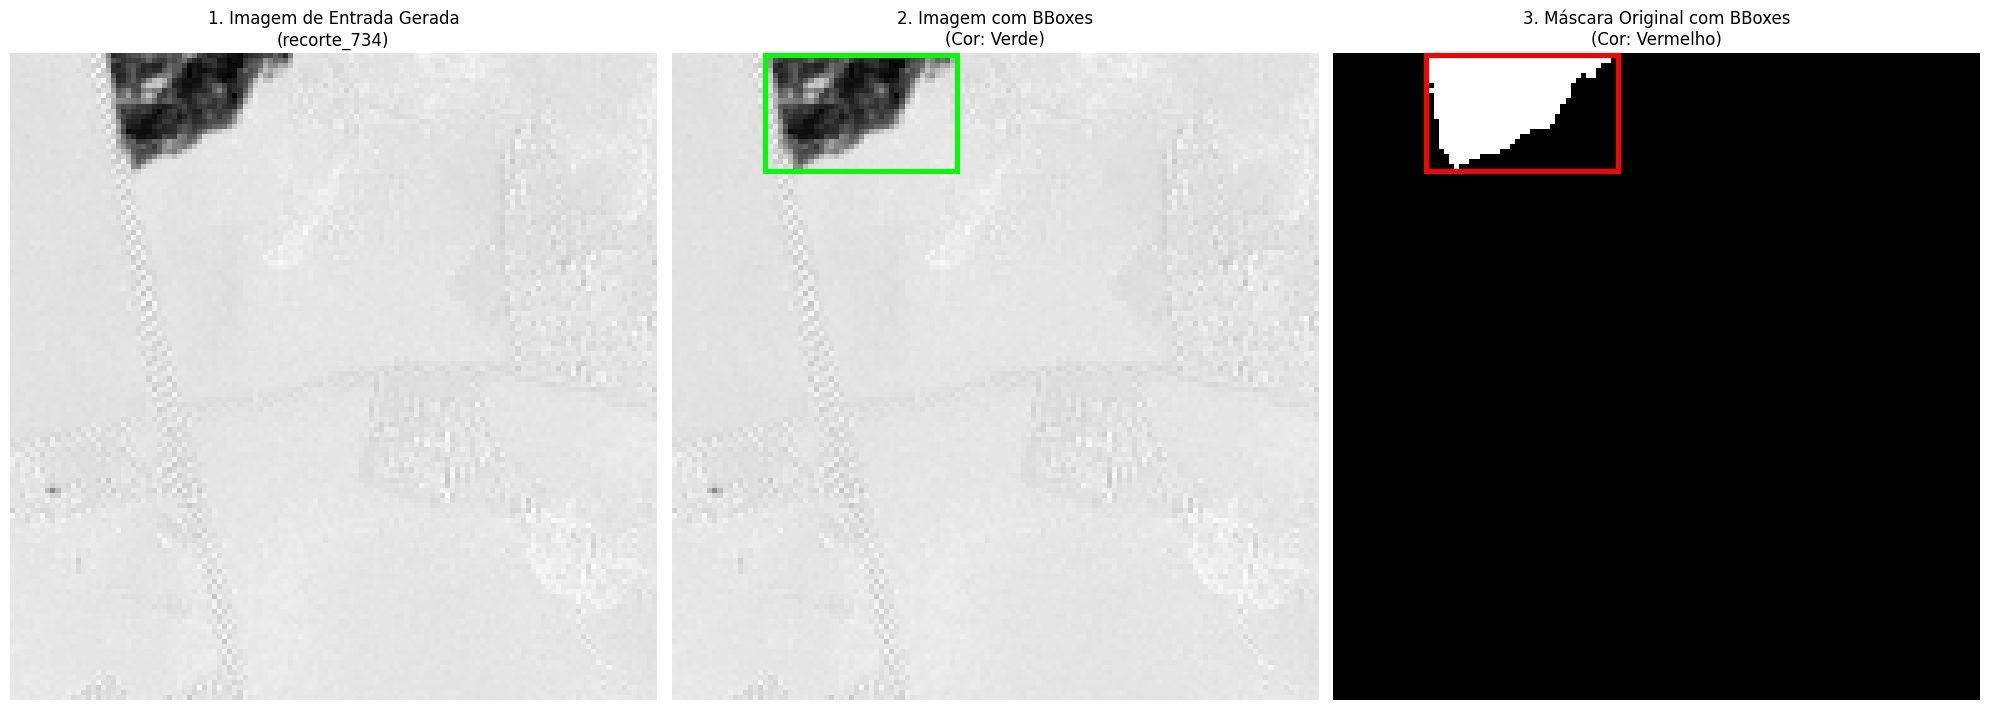

In [13]:
sample_name = 'recorte_734'
view_result(sample_name, data_original, data_folder)

### Cálculo de mean e std

In [14]:
mean_Diff, std_Diff  = calculate_mean_std_on_the_fly(data_folder, data_original)

Calculando média e desvio padrão para 537 imagens de treino...


100%|██████████| 537/537 [00:44<00:00, 12.19it/s]


### treinamento do SSD

In [29]:
train_main(data_folder, data_original, mean_Diff, std_Diff, check_continue = False)

/mnt/c/Users/Murilo/Desktop/worcap/venv/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/mnt/c/Users/Murilo/Desktop/worcap/venv/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



Loaded base model.



/mnt/c/Users/Murilo/Desktop/worcap/venv/lib/python3.10/site-packages/torch/nn/_reduction.py:51: UserWarning: size_average and reduce args will be deprecated, please use reduction='none' instead.
  warnings.warn(warning.format(ret))


Epoch: [0][0/34]	Batch Time 33.992 (33.992)	Data Time 2.165 (2.165)	Loss 14.5584 (14.5584)	
Epoch: [1][0/34]	Batch Time 3.587 (3.587)	Data Time 2.136 (2.136)	Loss 5.4445 (5.4445)	
Epoch: [2][0/34]	Batch Time 2.975 (2.975)	Data Time 1.830 (1.830)	Loss 8.5698 (8.5698)	
Epoch: [3][0/34]	Batch Time 3.110 (3.110)	Data Time 1.910 (1.910)	Loss 4.6026 (4.6026)	
Epoch: [4][0/34]	Batch Time 3.823 (3.823)	Data Time 2.370 (2.370)	Loss 7.6114 (7.6114)	
Epoch: [5][0/34]	Batch Time 3.629 (3.629)	Data Time 2.121 (2.121)	Loss 3.9760 (3.9760)	
Epoch: [6][0/34]	Batch Time 3.222 (3.222)	Data Time 2.059 (2.059)	Loss 4.3822 (4.3822)	
Epoch: [7][0/34]	Batch Time 3.746 (3.746)	Data Time 2.524 (2.524)	Loss 4.7686 (4.7686)	
Epoch: [8][0/34]	Batch Time 3.224 (3.224)	Data Time 2.059 (2.059)	Loss 4.8986 (4.8986)	
Epoch: [9][0/34]	Batch Time 3.871 (3.871)	Data Time 2.589 (2.589)	Loss 4.1178 (4.1178)	
Epoch: [10][0/34]	Batch Time 4.201 (4.201)	Data Time 2.894 (2.894)	Loss 4.0327 (4.0327)	
Epoch: [11][0/34]	Batch Tim

KeyboardInterrupt: 

### Validação


Loaded checkpoint from epoch 1506.



/tmp/ipykernel_4117/758936025.py:493: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at /pytorch/aten/src/ATen/native/IndexingUtils.h:29.)
  image_boxes.append(class_decoded_locs[1 - suppress])
/tmp/ipykernel_4117/758936025.py:495: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at /pytorch/aten/src/ATen/native/IndexingUtils.h:29.)
  image_scores.append(class_scores[1 - suppress])


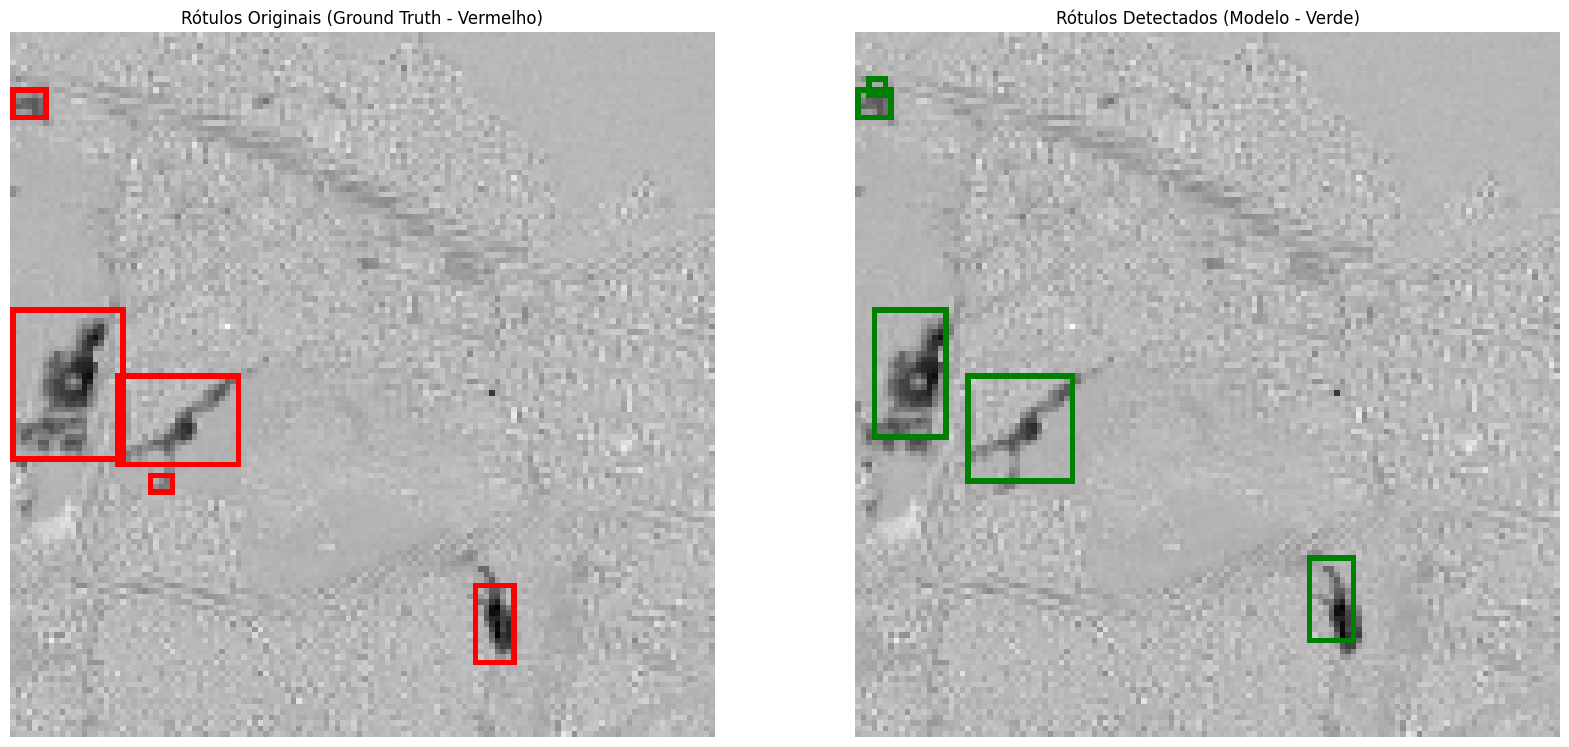

In [15]:
basename = 'recorte_99'
detect_Bbox_Compare(basename, data_folder , data_original,
                        mean_Diff, std_Diff, 
                        min_score=0.15, max_overlap=0.15, top_k=20)

### Eval

In [53]:
evaluate_main(data_folder, data_original, 
              mean_Diff, std_Diff, 
              batch_size = batch_size, workers = 4)

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]/tmp/ipykernel_1361/758936025.py:493: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at /pytorch/aten/src/ATen/native/IndexingUtils.h:29.)
  image_boxes.append(class_decoded_locs[1 - suppress])
/tmp/ipykernel_1361/758936025.py:495: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at /pytorch/aten/src/ATen/native/IndexingUtils.h:29.)
  image_scores.append(class_scores[1 - suppress])
Evaluating: 100%|██████████| 2/2 [02:44<00:00, 82.02s/it]


{'burn_scar': 0.44800621271133423}

Mean Average Precision (mAP): 0.448


---
# FCN

## Funções auxiliares

### Parâmetros e Variáveis

In [16]:
# parâmetros de treino
device = "cuda" if torch.cuda.is_available() else "cpu"
gpu_index = 0
load_num = 0
batch_size = 32
layers = 8
num_workers = 8
epochs = 100
channels = 1
input_size = [channels, 32, 32]
learning_rate = 0.001

### Para criação do dataset que o FCN espera

In [17]:
def adjust_bbox(xmin, ymin, xmax, ymax, img_height, img_width, min_size=8):
    """
    Ajusta uma bounding box para ser quadrada e ter um tamanho mínimo,
    garantindo que ela não ultrapasse os limites da imagem.
    """
    width = xmax - xmin
    height = ymax - ymin
    max_dim = max(width, height)
    
    center_x = xmin + width / 2
    center_y = ymin + height / 2
    
    new_xmin = int(center_x - max_dim / 2)
    new_ymin = int(center_y - max_dim / 2)
    new_xmax = int(new_xmin + max_dim)
    new_ymax = int(new_ymin + max_dim)

    current_size = new_xmax - new_xmin
    if current_size < min_size:
        new_xmin = int(center_x - min_size / 2)
        new_ymin = int(center_y - min_size / 2)
        new_xmax = int(new_xmin + min_size)
        new_ymax = int(new_ymin + min_size)

    if new_xmin < 0:
        shift = -new_xmin
        new_xmin = 0
        new_xmax += shift
    if new_ymin < 0:
        shift = -new_ymin
        new_ymin = 0
        new_ymax += shift
        
    if new_xmax > img_width:
        shift = new_xmax - img_width
        new_xmax = img_width
        new_xmin -= shift
    if new_ymax > img_height:
        shift = new_ymax - img_height
        new_ymax = img_height
        new_ymin -= shift
        
    if new_xmin < 0: new_xmin = 0
    if new_ymin < 0: new_ymin = 0
    
    return new_xmin, new_ymin, new_xmax, new_ymax

def get_padded_size(size, multiple=32):
    """Calcula o próximo múltiplo de 'multiple' para um dado tamanho."""
    return int(math.ceil(size / multiple)) * multiple

def extract_processed_patches(data_folder, original_folder,
                                 target_size=(32, 32)):
    """
    Extrai patches de imagem e máscara, aplicando lógicas de ajuste e redimensionamento.
    """
    
    annotations_folder = os.path.join(data_folder, 'Annotations')
    t1_folder = os.path.join(original_folder, 't1')
    t2_folder = os.path.join(original_folder, 't2')
    mask_folder = os.path.join(original_folder, 'mask')
    output_folder = f'Bbox_diff'

    output_images_path = os.path.join(output_folder, 'dataset')
    output_masks_path = os.path.join(output_folder, 'mask')
    os.makedirs(output_folder, exist_ok=True)
    os.makedirs(output_images_path, exist_ok=True)
    os.makedirs(output_masks_path, exist_ok=True)
    

    xml_files = [f for f in os.listdir(annotations_folder) if f.endswith('.xml')]
    print(f"Iniciando extração de patches de {len(xml_files)} recortes")

    
    global_patch_counter = 0
    for xml_filename in tqdm(xml_files, desc="Processando recortes"):
        basename = os.path.splitext(xml_filename)[0]
        
        t1_path = os.path.join(t1_folder, basename + '.tif')
        t2_path = os.path.join(t2_folder, basename + '.tif')
        mask_path = os.path.join(mask_folder, basename + '.tif')

        if not all(os.path.exists(p) for p in [t1_path, t2_path, mask_path]):
            print(f"\nAviso: Arquivos não encontrados para '{basename}'. Pulando.")
            continue

        with rasterio.open(t1_path) as src: t1_b3, t1_b4 = src.read(3).astype(np.float32), src.read(4).astype(np.float32)
        with rasterio.open(t2_path) as src: t2_b3, t2_b4 = src.read(3).astype(np.float32), src.read(4).astype(np.float32)
        with rasterio.open(mask_path) as src: mask_data = src.read(1)

        img_height, img_width = mask_data.shape
        idx1 = spyndex.computeIndex(index=["NBRSWIR"], params={"S1": t1_b3, "S2": t1_b4})
        idx2 = spyndex.computeIndex(index=["NBRSWIR"], params={"S1": t2_b3, "S2": t2_b4})
        source_image = idx1 - idx2 
        
        xml_path = os.path.join(annotations_folder, xml_filename)
        tree = ET.parse(xml_path)
        root = tree.getroot()
        
        for obj in root.findall('object'):
            bndbox = obj.find('bndbox')
            xmin, ymin = int(bndbox.find('xmin').text), int(bndbox.find('ymin').text)
            xmax, ymax = int(bndbox.find('xmax').text), int(bndbox.find('ymax').text)

            final_xmin, final_ymin, final_xmax, final_ymax = adjust_bbox(xmin, ymin, xmax, ymax, img_height, img_width)
            
            image_patch = source_image[final_ymin:final_ymax, final_xmin:final_xmax]
            mask_patch = mask_data[final_ymin:final_ymax, final_xmin:final_xmax]

            h, w = image_patch.shape

            if h <= 32 and w <= 32:
                padded_image_patch = np.zeros(target_size, dtype=np.float32)
                padded_image_patch[:h, :w] = image_patch
                
                padded_mask_patch = np.zeros(target_size, dtype=mask_data.dtype)
                padded_mask_patch[:h, :w] = mask_patch

                global_patch_counter += 1
                profile = {'driver': 'GTiff', 'height': 32, 'width': 32, 'count': 1,
                           'dtype': padded_image_patch.dtype, 'crs': None, 'transform': from_origin(0, 0, 1, 1)}
                
                img_path = os.path.join(output_images_path, f"patch_{global_patch_counter}.tif")
                mask_path = os.path.join(output_masks_path, f"patch_{global_patch_counter}.tif")

                with rasterio.open(img_path, 'w', **profile) as dst: dst.write(padded_image_patch, 1)
                with rasterio.open(mask_path, 'w', **profile) as dst: dst.write(padded_mask_patch.astype(profile['dtype']), 1)

            else:
                padded_h = get_padded_size(h, 32)
                padded_w = get_padded_size(w, 32)
                
                padded_image_patch = np.zeros((padded_h, padded_w), dtype=np.float32)
                padded_image_patch[:h, :w] = image_patch
                
                padded_mask_patch = np.zeros((padded_h, padded_w), dtype=mask_data.dtype)
                padded_mask_patch[:h, :w] = mask_patch
                
                for i in range(0, padded_h, 32):
                    for j in range(0, padded_w, 32):
                        image_slice = padded_image_patch[i:i+32, j:j+32]
                        mask_slice = padded_mask_patch[i:i+32, j:j+32]
                        
                        global_patch_counter += 1
                
                        profile = {'driver': 'GTiff', 'height': 32, 'width': 32, 'count': 1,
                                   'dtype': image_slice.dtype, 'crs': None, 'transform': from_origin(0, 0, 1, 1)}

                        img_path = os.path.join(output_images_path, f"patch_{global_patch_counter}.tif")
                        mask_path = os.path.join(output_masks_path, f"patch_{global_patch_counter}.tif")

                        with rasterio.open(img_path, 'w', **profile) as dst: dst.write(image_slice, 1)
                        with rasterio.open(mask_path, 'w', **profile) as dst: dst.write(mask_slice.astype(profile['dtype']), 1)
    
    print(f"\nProcesso concluído! {global_patch_counter} patches de 32x32 foram gerados.")

def make_split_csv(dataset_dir):
   
    patch_files = [f for f in os.listdir(dataset_dir) if f.startswith("patch_") and f.endswith(".tif")]

   
    ids = [int(f.split("_")[1].replace(".tif", "")) for f in patch_files]
    ids.sort()

    random.seed(42)
    random.shuffle(ids)

    n_total = len(ids)
    n_train = int(n_total * 0.8)
    train_ids = ids[:n_train]
    val_ids = ids[n_train:]

    df = pd.DataFrame({
        "ID": train_ids + val_ids,
        "split": ["train"] * len(train_ids) + ["val"] * len(val_ids)
    })

    # Salva CSV
    df.to_csv(os.path.join("Bbox_diff", "split_diff_ids.csv"), index=False)

    print(f"Arquivo split_diff_ids.csv criado com {len(train_ids)} para treino e {len(val_ids)} para validação.")

### Funções principais do FCN

In [18]:
# Datalouder
class WorCapDataset(Dataset):
    def __init__(self, diff_dir, mask_dir, ids, transform=None):
        self.diff_dir = diff_dir
        self.mask_dir = mask_dir
        self.ids = ids
        self.transform = transform
        
    def __len__(self):
        return len(self.ids)

    def read_image(self, path):
        with rasterio.open(path) as src:
            img = src.read().astype(np.float32)
            img = np.nan_to_num(img, nan=0.0)
            img_min = img.min()
            img_max = img.max()
            if img_max - img_min > 0:
                img = (img - img_min) / (img_max - img_min)
            else:
                img = np.zeros_like(img)
        return torch.tensor(img, dtype=torch.float32)

    def read_mask(self, path):
        with rasterio.open(path) as src:
            mask = src.read(1).astype(np.float32)
            mask = np.nan_to_num(mask, nan=0.0)
            mask = np.where(mask > 0, 1.0, 0.0)
        return torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

    def __getitem__(self, idx):
        id_ = self.ids[idx]
        fname = f"patch_{id_}.tif"
        diff_path = os.path.join(self.diff_dir, fname)
        mask_path = os.path.join(self.mask_dir, fname)

        img = self.read_image(diff_path)
        mask = self.read_mask(mask_path)

        if self.transform:
            img = self.transform(img)
            mask = self.transform(mask)

        return img, mask, id_

In [19]:
#Loss
class DiceLoss(nn.Module):
    def __init__(self, weight=None, size_average=True):
        super(DiceLoss, self).__init__()

    def forward(self, inputs, targets, smooth=1):
        # comment out if your model contains a sigmoid or equivalent activation layer
        inputs = F.sigmoid(inputs)
        N = inputs.size()[0]
        
        # flatten label and prediction tensors
        inputs = inputs.contiguous().view(N, -1)
        targets = targets.contiguous().view(N, -1)

        intersection = (inputs * targets).sum(1)
        dice = (2. * intersection + smooth) / (inputs.sum(1) + targets.sum(1) + smooth)

        return 1 - dice.sum() / N

In [20]:
# FCN_2D
class Unet_module(nn.Module):
    def __init__(self, kernel_size, de_kernel_size, channel_list, down_up='down'):
        super(Unet_module, self).__init__()
        self.conv1 = nn.Conv2d(channel_list[0], channel_list[1], kernel_size, 1, (kernel_size - 1) // 2)
        self.conv2 = nn.Conv2d(channel_list[1], channel_list[2], kernel_size, 1, (kernel_size - 1) // 2)
        self.relu1 = nn.PReLU()
        self.relu2 = nn.PReLU()
        self.bn1 = nn.BatchNorm2d(channel_list[1])
        self.bn2 = nn.BatchNorm2d(channel_list[2])
        self.bridge_conv = nn.Conv2d(channel_list[0], channel_list[-1], kernel_size, 1, (kernel_size - 1) // 2)

        if down_up == 'down':
            self.sample = nn.Sequential(
                nn.Conv2d(channel_list[2], channel_list[2], de_kernel_size, 2, (de_kernel_size - 1) // 2, 1),
                nn.BatchNorm2d(channel_list[2]), nn.PReLU())
        else:
            self.sample = nn.Sequential(
                nn.ConvTranspose2d(channel_list[2], channel_list[2], de_kernel_size, 2, (de_kernel_size - 1) // 2),
                nn.BatchNorm2d(channel_list[2]), nn.ReLU())

    def forward(self, x):
        res = self.bridge_conv(x)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu1(x)
        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu2(x)
        x = x + res
        next_layer = self.sample(x)

        return next_layer, x
    
class de_conv_module(nn.Module):
    def __init__(self, kernel_size, de_kernel_size, channel_list, down_up='down'):
        super().__init__()
        self.conv1 = nn.Conv2d(channel_list[0], channel_list[1], kernel_size, 1, (kernel_size - 1) // 2)
        self.conv2 = nn.Conv2d(channel_list[1], channel_list[2], kernel_size, 1, (kernel_size - 1) // 2)
        self.relu1 = nn.PReLU()
        self.relu2 = nn.PReLU()
        self.bn1 = nn.BatchNorm2d(channel_list[1])
        self.bn2 = nn.BatchNorm2d(channel_list[2])
        self.bridge_conv = nn.Conv2d(channel_list[0], channel_list[-1], kernel_size, 1, (kernel_size - 1) // 2)

        if down_up == 'down':
            self.sample = nn.Sequential(
                nn.Conv2d(channel_list[2], channel_list[2], de_kernel_size, 2, (de_kernel_size - 1) // 2, 1),
                nn.BatchNorm2d(channel_list[2]), nn.PReLU())
        else:
            self.sample = nn.Sequential(
                nn.ConvTranspose2d(channel_list[2], channel_list[2], de_kernel_size, 2, (de_kernel_size - 1) // 2),
                nn.BatchNorm2d(channel_list[2]), nn.ReLU())

    def forward(self, x, x1):
        x = torch.cat([x, x1], dim=1)
        res = self.bridge_conv(x)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu1(x)
        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu2(x)
        x = x + res
        next_layer = self.sample(x)

        return next_layer

class FCN_2D(nn.Module):
    def __init__(self, in_channel, layers):
        super().__init__()
        # channel=2
        self.conv1 = nn.Sequential(nn.Conv2d(in_channel, layers, 5, 1, padding=2), nn.BatchNorm2d(layers), nn.PReLU())
        self.conv2 = nn.Sequential(nn.Conv2d(layers, layers * 2, 2, 2, padding=0), nn.BatchNorm2d(layers * 2),
                                   nn.PReLU())
        self.conv3 = Unet_module(5, 2, [layers * 2, layers * 2, layers * 4], 'down')
        self.conv4 = Unet_module(5, 2, [layers * 4, layers * 4, layers * 8], 'down')
        self.conv5 = Unet_module(5, 2, [layers * 8, layers * 8, layers * 16], 'down')

        self.de_conv1 = Unet_module(5, 2, [layers * 16, layers * 32, layers * 16], down_up='up')
        self.de_conv2 = de_conv_module(5, 2, [layers * 32, layers * 8, layers * 8], down_up='up')
        self.de_conv3 = de_conv_module(5, 2, [layers * 16, layers * 4, layers * 4], down_up='up')
        self.de_conv4 = de_conv_module(5, 2, [layers * 8, layers * 2, layers], down_up='up')

        self.last_conv = nn.Conv2d(layers * 2, 1, 1, 1, padding=0)

    def forward(self, x):
        x = self.conv1(x)
        x_1 = x
        x = self.conv2(x)
        x, x_2 = self.conv3(x)
        x, x_3 = self.conv4(x)
        x, x_4 = self.conv5(x)

        x, _ = self.de_conv1(x)
        x = self.de_conv2(x, x_4)
        x = self.de_conv3(x, x_3)
        x = self.de_conv4(x, x_2)

        x = torch.cat([x, x_1], dim=1)
        output = self.last_conv(x)
        return output


In [21]:
# Train e Valid
def train(model, criterion, train_loader, opt, device, e):
    model = model.to(device)
    model.train()
    train_sum = 0
    for j, batch in enumerate(train_loader):
        #print(batch[0].shape, batch[1].shape)
        img, label = batch[0].float(), batch[1].float()
        img, label = img.to(device), label.to(device)
        outputs = model(img)
        opt.zero_grad()
        loss = criterion(outputs, label)
        print('Epoch {:<3d}  |  Step {:>3d}/{:<3d}  | train loss {:.4f}'.format(e, j, len(train_loader), loss.item()))
        train_sum += loss.item()
        loss.backward()
        opt.step()
    return train_sum / len(train_loader)


def valid(model, criterion, valid_loader, device, e):
    model.eval()
    valid_sum = 0
    for j, batch in enumerate(valid_loader):
        img, label = batch[0].float(), batch[1].float()
        img, label = img.to(device), label.to(device)

        with torch.no_grad():
            outputs = model(img)
            loss = criterion(outputs, label)
        valid_sum += loss.item()
        print('Epoch {:<3d}  |Step {:>3d}/{:<3d}  | valid loss {:.4f}'.format(e, j, len(valid_loader), loss.item()))

    return valid_sum / len(valid_loader)

In [22]:
# Infer
def inference(model, valid_loader, device, save_img_path):
    model.eval()
    for i, batch in enumerate(valid_loader):
        img, label, id = batch[0].float(), batch[1].float(), str(batch[2].item())
        img, label = img.to(device), label.to(device)

        with torch.no_grad():
            outputs = model(img)
        outputs = torch.sigmoid(outputs)
        outputs = outputs.squeeze(1)
        prediction = outputs.cpu().detach().numpy()
        
        #prediction[prediction >= 0.5] = 1
        #prediction[prediction < 0.5] = 0

        with open(os.path.join(save_img_path, f'patch_{id}.pkl'), 'wb') as f:
            pickle.dump(prediction, f)

### Funções para modularização

In [23]:
# Treinamento

def setup_environment(gpu_index, result_path, channels, layers):
    """
    Configura o ambiente de execução, incluindo caminhos e dispositivo.

    :param gpu_index: (int) O índice da GPU a ser utilizada.
    :param result_path: (str) O caminho base para a pasta de resultados.
    :param channels: (int) O número de canais de entrada do modelo.
    :param layers: (int) O número de camadas ou features do modelo.
    :return: (tuple) Uma tupla contendo o caminho para salvar o modelo (str) e
             o dispositivo de processamento (torch.device).
    """
    model_save_path = os.path.join(result_path, f'FCN_2D_{channels}ch_{layers}lyr')
    os.makedirs(model_save_path, exist_ok=True)

    os.environ['CUDA_VISIBLE_DEVICES'] = str(gpu_index)
    torch.cuda.set_device(0)
    torch.backends.cudnn.enabled = True
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Ambiente configurado. Usando dispositivo: {device}")
    print(f"Checkpoints serão salvos em: {model_save_path}")
    return model_save_path, device

def create_dataloaders(data_paths, train_ids, val_ids, batch_size, num_workers):
    """
    Cria os DataLoaders para os conjuntos de treino e validação.

    :param data_paths: (dict) Dicionário com os caminhos para as imagens ('diff') e máscaras ('mask').
    :param train_ids: (list) Lista de IDs para o conjunto de treino.
    :param val_ids: (list) Lista de IDs para o conjunto de validação.
    :param batch_size: (int) O tamanho do lote (batch).
    :param num_workers: (int) O número de workers para o carregamento de dados.
    :return: (tuple) Uma tupla contendo o train_loader e o test_loader.
    """
    dataset_train = WorCapDataset(data_paths["diff"], data_paths['mask'], train_ids)
    dataset_val = WorCapDataset(data_paths["diff"], data_paths['mask'], val_ids)

    train_loader = DataLoader(dataset_train, batch_size=batch_size, shuffle=True, num_workers=num_workers)
    test_loader = DataLoader(dataset_val, batch_size=batch_size, shuffle=False, num_workers=num_workers)
    
    print(f"DataLoaders criados: {len(dataset_train)} amostras de treino, {len(dataset_val)} de validação.")
    return train_loader, test_loader

def build_or_load_model(device, channels, layers, load_num=0, model_save_path=''):
    """
    Constrói um novo modelo FCN_2D ou carrega um checkpoint existente.

    :param device: (torch.device) O dispositivo para alocar o modelo.
    :param channels: (int) Número de canais de entrada.
    :param layers: (int) Número de camadas/features.
    :param load_num: (int, opcional) O número da época do checkpoint a ser carregado. Se 0, inicializa um novo modelo.
    :param model_save_path: (str, opcional) Caminho para a pasta de checkpoints.
    :return: (torch.nn.Module) O modelo FCN_2D inicializado ou carregado.
    """
    net = FCN_2D(channels, layers).to(device)
    
    if load_num == 0:
        print("Inicializando um novo modelo com pesos ortogonais...")
        for m in net.modules():
            if isinstance(m, (nn.Conv3d)): 
                nn.init.orthogonal_(m.weight)
    else:
        checkpoint_path = os.path.join(model_save_path, f'net_{load_num}.pkl')
        print(f"Carregando modelo do checkpoint: {checkpoint_path}")
        net.load_state_dict(torch.load(checkpoint_path))
    
    return net

def load_training_records(load_num, model_save_path):
    """
    Carrega o histórico de treinamento de um arquivo CSV ou inicializa um novo.

    :param load_num: (int) A época a partir da qual o treino está sendo retomado.
    :param model_save_path: (str) O caminho para a pasta onde o 'train_record.csv' está salvo.
    :return: (dict) Um dicionário contendo as listas do histórico de treino.
    """
    if load_num == 0:
        print("Iniciando um novo registro de treinamento.")
        return {'epoch': [], 'train_loss': [], 'valid_loss': [], 'duration': []}
    else:
        print("Carregando registro de treinamento existente...")
        records_path = os.path.join(model_save_path, 'train_record.csv')
        records = pd.read_csv(records_path)
        return {
            'epoch': records['epoch'].tolist(),
            'train_loss': records['train_loss'].tolist(),
            'valid_loss': records['valid_loss'].tolist(),
            'duration': records['duration'].tolist()
        }

def run_training_loop(net, criterion, train_loader, test_loader, net_opt, device, 
                      start_epoch, total_epochs, history, model_save_path):
    """
    Executa o loop principal de treinamento e validação por várias épocas.

    :param net: O modelo a ser treinado.
    :param criterion: A função de perda.
    :param train_loader: O DataLoader de treino.
    :param test_loader: O DataLoader de validação/teste.
    :param net_opt: O otimizador.
    :param device: O dispositivo de processamento.
    :param start_epoch: A época inicial.
    :param total_epochs: O número total de épocas para treinar.
    :param history: (dict) O dicionário com o histórico de treino a ser atualizado.
    :param model_save_path: (str) O caminho para salvar os checkpoints.
    :return: (dict) O dicionário de histórico atualizado.
    """
    for e in range(start_epoch, total_epochs):
        time_start = time.time()
        print(f"\n--- Época {e}/{total_epochs - 1} ---")
        
        print("============= Treino =============")
        train_loss = train(net, criterion, train_loader, net_opt, device, e)
        
        print("============= Validação =============")
        valid_loss = valid(net, criterion, test_loader, device, e)

        # Atualiza o histórico
        history['train_loss'].append(train_loss)
        history['valid_loss'].append(valid_loss)
        history['epoch'].append(e)
        duration = time.time() - time_start
        history['duration'].append(duration)
        
        print(f"Época {e} concluída em {duration:.2f}s | "
              f"Train Loss: {train_loss:.4f} | Valid Loss: {valid_loss:.4f}")
        
        # Salva o checkpoint
        if (e + 1) % 5 == 0 or e == (total_epochs - 1):
            checkpoint_path = os.path.join(model_save_path, f'net_{e+1}.pkl')
            torch.save(net.state_dict(), checkpoint_path)
            print(f"Checkpoint salvo em: {checkpoint_path}")
            
    return history

def save_training_records(history, model_save_path):
    """
    Salva o dicionário de histórico de treinamento em um arquivo CSV.

    :param history: (dict) O dicionário de histórico completo.
    :param model_save_path: (str) O caminho para a pasta onde o CSV será salvo.
    :return: None
    """
    record_df = pd.DataFrame(history)
    record_df.to_csv(os.path.join(model_save_path, 'train_record.csv'), index=False)
    print(f"\nRegistro de treinamento salvo em '{os.path.join(model_save_path, 'train_record.csv')}'")

In [24]:
# infer

def setup_inference_environment(result_path, channels, layers, gpu_index=0):
    """
    Configura os caminhos de saída e o dispositivo para a inferência.

    :param result_path: (str) O caminho base para a pasta de resultados.
    :param channels: (int) O número de canais de entrada do modelo.
    :param layers: (int) O número de camadas ou features do modelo.
    :param gpu_index: (int) O índice da GPU a ser utilizada.
    :return: (tuple) Uma tupla contendo o caminho base do modelo (str), o caminho
             de saída da inferência (str) e o dispositivo de processamento (torch.device).
    """
    model_save_path = os.path.join(result_path, f'FCN_2D_{channels}ch_{layers}lyr')
    infer_path = os.path.join(model_save_path, 'infer')
    os.makedirs(infer_path, exist_ok=True)

    os.environ['CUDA_VISIBLE_DEVICES'] = str(gpu_index)
    torch.cuda.set_device(0)
    torch.backends.cudnn.enabled = True
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    print(f"Ambiente de inferência configurado. Usando dispositivo: {device}")
    print(f"Predições serão salvas em: {infer_path}")
    return model_save_path, infer_path, device

def create_inference_loader(data_paths, val_ids, num_workers=8):
    """
    Cria o DataLoader para o conjunto de dados de inferência/validação.

    :param data_paths: (dict) Dicionário com os caminhos para as imagens e máscaras.
    :param val_ids: (list) Lista de IDs para o conjunto de validação/inferência.
    :param num_workers: (int) O número de workers para o carregamento de dados.
    :return: (DataLoader) O DataLoader para o conjunto de teste.
    """
    dataset_val = WorCapDataset(data_paths["diff"], data_paths['mask'], val_ids)
    test_loader = DataLoader(dataset_val, batch_size=1, shuffle=False, num_workers=num_workers)
    print(f"DataLoader de inferência criado com {len(dataset_val)} amostras.")
    return test_loader


In [25]:
#View infer

def read_mask(path):
    """Lê um arquivo de máscara .tif e retorna um array NumPy binário."""
    with rasterio.open(path) as src:
        mask = (src.read(1) > 0).astype(np.uint8)
    return mask

def read_pickle(path):
    """Lê um arquivo .pkl e retorna seu conteúdo."""
    with open(path, 'rb') as f:
        data = pickle.load(f)
    return data

def calc_dice(true_mask, pred_mask, smooth=1):
    """Calcula o coeficiente Dice entre duas máscaras binárias."""
    intersection = np.sum(pred_mask * true_mask)
    return (2. * intersection + smooth) / (np.sum(pred_mask) + np.sum(true_mask) + smooth)


def calculate_metrics(train_config, val_ids, result_path, data_paths):
    """
    Calcula métricas (Dice, contagem de pixels) para um conjunto de predições.

    A função itera sobre um conjunto de validação, carrega as máscaras de referência
    e as máscaras preditas (salvas como .pkl), calcula o Dice score para cada uma,
    e prepara os dados para a curva ROC.

    :param train_config: (dict) Dicionário com a configuração do modelo (ex: {'channels': 1, 'layers': 8}).
    :param val_ids: (list) Lista de IDs (inteiros) a serem avaliados.
    :param result_path: (str) Caminho para a pasta de resultados.
    :param data_paths: (dict) Dicionário com os caminhos para os patches de imagem e máscara.
    :return: (tuple) Uma tupla contendo:
             - dices_dict (dict): Dicionário com os scores de Dice e contagem de pixels.
             - all_labels_flat (list): Lista achatada de todos os pixels das máscaras de referência.
             - all_preds_flat (list): Lista achatada de todas as probabilidades de pixel preditas.
    """
    channels = train_config['channels']
    layers = train_config['layers']
    train_name = f'FCN_2D_{channels}ch_{layers}lyr'
    file_path = os.path.join(result_path, train_name, 'infer')

    all_labels_flat = []
    all_preds_flat = []
    
    dices_dict = {
        f'{layers}_layers': {},
        'numero_mask': {}
    }

    print(f"\nCalculando métricas para o modelo: {train_name}")
    for r in tqdm(val_ids, desc="Processando Patches"):
        mask = read_mask(os.path.join(data_paths['mask'], f'patch_{r}.tif'))
        pickle_pred = read_pickle(os.path.join(file_path, f'patch_{r}.pkl'))
        pred_prob = np.array(pickle_pred).squeeze()
        
        # Armazena a contagem de pixels positivos na máscara real
        dices_dict['numero_mask'][r] = np.sum(mask)
        
        # Calcula o Dice Score com a máscara binarizada
        pred_binary = (pred_prob >= 0.5).astype(np.float32)
        dice = calc_dice(mask, pred_binary)
        dices_dict[f'{layers}_layers'][r] = dice 
        
        # Estende as listas para a curva ROC
        all_labels_flat.extend(mask.ravel())
        all_preds_flat.extend(pred_prob.ravel())
        
    return dices_dict, all_labels_flat, all_preds_flat

def save_dices_to_csv(dices_dict, output_path='dices_infer.csv'):
    """
    Converte um dicionário de scores Dice em um DataFrame e o salva como .csv.

    :param dices_dict: (dict) O dicionário gerado por `calculate_metrics`.
    :param output_path: (str) O caminho para o arquivo .csv de saída.
    :return: (pd.DataFrame) O DataFrame criado.
    """
    df_dices = pd.DataFrame(dices_dict)
    df_dices.index.name = 'patch'
    # Reordena colunas para melhor visualização
    cols = df_dices.columns.tolist()
    cols = ['numero_mask'] + [col for col in cols if col != 'numero_mask']
    df_dices = df_dices[cols]
    df_dices.to_csv(output_path)
    print(f"Scores de Dice salvos em '{output_path}'")
    return df_dices

def plot_dice_histogram(dices_df):
    """
    Plota um histograma da distribuição dos scores de Dice para cada modelo avaliado.

    :param dices_df: (pd.DataFrame) O DataFrame contendo os scores de Dice.
    :return: None
    """
    # Filtra para incluir apenas patches que tinham uma máscara de referência não vazia
    df_with_mask = dices_df[dices_df['numero_mask'] > 0]

    for col_name in df_with_mask.columns:
        if col_name == 'numero_mask':
            continue
        
        median_dice = df_with_mask[col_name].median()
        mean_dice = df_with_mask[col_name].mean()
        q1 = df_with_mask[col_name].quantile(0.25)
        q3 = df_with_mask[col_name].quantile(0.75)
        
        plt.figure(figsize=(8, 5))
        plt.hist(df_with_mask[col_name], bins=20, edgecolor='black', color='#0072B2')
        plt.title(f'Histograma dos Scores de Dice - {col_name}')
        plt.xlabel('Dice Score')
        plt.ylabel('Frequência')
        plt.axvline(median_dice, color='#D55E00', linestyle='--', linewidth=1.5, label=f'Mediana ({median_dice:.3f})')
        plt.axvline(mean_dice, color='#009E73', linestyle='--', linewidth=1.5, label=f'Média ({mean_dice:.3f})')
        plt.axvline(q1, color='#CC79A7', linestyle=':', linewidth=1, label=f'1º Quartil ({q1:.3f})')
        plt.axvline(q3, color='#F0E442', linestyle=':', linewidth=1, label=f'3º Quartil ({q3:.3f})')
        plt.legend()
        plt.grid(axis='y', alpha=0.5)
        plt.show()

def plot_roc_curve(y_true, y_scores, model_name):
    """
    Calcula e plota a curva ROC e o valor AUC.

    :param y_true: (array) Array achatado com os rótulos verdadeiros (0s e 1s).
    :param y_scores: (array) Array achatado com as probabilidades preditas (0.0 a 1.0).
    :param model_name: (str) O nome do modelo para usar no título do gráfico.
    :return: None
    """
    auc = roc_auc_score(y_true, y_scores)
    fpr, tpr, _ = roc_curve(y_true, y_scores)

    plt.figure(figsize=(7, 7))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f"AUC = {auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
    plt.xlabel("Taxa de Falsos Positivos")
    plt.ylabel("Taxa de Verdadeiros Positivos")
    plt.title(f"Curva ROC - {model_name}")
    plt.legend()
    plt.grid(alpha=0.5)
    plt.show()
    
def plot_training_history(records_df, model_name):
    """
    Plota as curvas de perda de treino e validação a partir de um DataFrame de histórico.
    
    :param records_df: (pd.DataFrame) DataFrame lido do arquivo 'train_record.csv'.
    :param model_name: (str) O nome do modelo para o título do gráfico.
    :return: None
    """
    plt.figure(figsize=(10, 5))
    plt.plot(records_df['epoch'], records_df['train_loss'], label='Perda de Treino')
    plt.plot(records_df['epoch'], records_df['valid_loss'], label='Perda de Validação')
    plt.title(f'Histórico de Perdas - {model_name}')
    plt.xlabel('Época')
    plt.ylabel('Dice Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

In [26]:
#view result
def read_image(path):
    with rasterio.open(path) as src:
        img = src.read(1).astype(np.float32)
        img = np.nan_to_num(img, nan=0.0)
        img_min = img.min()
        img_max = img.max()
        if img_max - img_min > 0:
            img = (img - img_min) / (img_max - img_min)
        else:
            img = np.zeros_like(img)
    return img


def plot_sample(diff, mask, pred, title):
    diff_img = diff
    mask_img = mask
    pred_img = pred

    fig, axs = plt.subplots(1, 3, figsize=(12, 4))
    axs[0].imshow(diff_img)
    axs[0].set_title("Bbox da diferença")
    axs[1].imshow(mask_img, cmap="gray")
    axs[1].set_title("Mask")
    axs[2].imshow(pred_img, cmap="gray")
    axs[2].set_title("Pred")
    for ax in axs:
        ax.axis('off')
    plt.suptitle(title)
    plt.show()

def get_best_worst_ids(df, column, n=10):
    sorted_df = df.sort_values(by=column)
    worst_ids = sorted_df.head(n).index.tolist()
    best_ids = sorted_df.tail(n).index.tolist()
    return best_ids, worst_ids



## Fluxo principal

### Parâmetros e Variáveis

In [27]:
data_folder = './BurnScarDataset_SSD'
data_original = './dataset_kaggle/dataset' #Iguais ao do SSD, apenas reproduzindo

data_paths = {
    'diff': 'Bbox_diff/dataset',
    'mask': 'Bbox_diff/mask'
}
result_path = os.path.abspath('.') + '/results'

train_name = f'FCN_2D_{channels}ch_{layers}lyr'

### Criação do dataset

In [51]:
extract_processed_patches(data_folder, data_original)
make_split_csv(data_paths['diff'])

Iniciando extração de patches de 945 recortes


Processando recortes:   0%|          | 1/945 [00:00<02:16,  6.94it/s]/mnt/c/Users/Murilo/Desktop/worcap/venv/lib/python3.10/site-packages/rasterio/__init__.py:366: NotGeoreferencedWarning: The given matrix is equal to Affine.identity or its flipped counterpart. GDAL may ignore this matrix and save no geotransform without raising an error. This behavior is somewhat driver-specific.
  dataset = writer(
Processando recortes: 100%|██████████| 945/945 [03:39<00:00,  4.30it/s]


Processo concluído! 2798 patches de 32x32 foram gerados.
Arquivo split_diff_ids.csv criado com 2238 para treino e 560 para validação.


In [28]:
split_paths = 'Bbox_diff/split_diff_ids.csv'
split_df = pd.read_csv(split_paths)
train_ids = split_df[split_df['split'] == 'train']['ID'].tolist()
val_ids = split_df[split_df['split'] == 'val']['ID'].tolist()

### Treinamento

In [60]:
model_save_path, device = setup_environment(gpu_index, result_path, channels, layers)

train_loader, test_loader = create_dataloaders(data_paths, train_ids, val_ids, batch_size, num_workers)

net = build_or_load_model(device, channels, layers, load_num, model_save_path)

net_opt = optim.Adam(net.parameters(), lr=learning_rate)
criterion = DiceLoss()

training_history = load_training_records(load_num, model_save_path)
start_epoch = load_num if load_num > 0 else 0

final_history = run_training_loop(
    net=net,
    criterion=criterion,
    train_loader=train_loader,
    test_loader=test_loader,
    net_opt=net_opt,
    device=device,
    start_epoch=start_epoch,
    total_epochs=epochs,
    history=training_history,
    model_save_path=model_save_path
)

# 7. Salvar o registro final
save_training_records(final_history, model_save_path)

print("\n--- Treinamento Concluído ---")

Ambiente configurado. Usando dispositivo: cuda
Checkpoints serão salvos em: /mnt/c/Users/Murilo/Desktop/worcap/results/FCN_2D_1ch_8lyr
DataLoaders criados: 2238 amostras de treino, 560 de validação.
Inicializando um novo modelo com pesos ortogonais...
Iniciando um novo registro de treinamento.

--- Época 0/99 ---
============= Treino =============
Epoch 0    |  Step   0/70   | train loss 0.8967
Epoch 0    |  Step   1/70   | train loss 0.8494
Epoch 0    |  Step   2/70   | train loss 0.8664
Epoch 0    |  Step   3/70   | train loss 0.8620
Epoch 0    |  Step   4/70   | train loss 0.8790
Epoch 0    |  Step   5/70   | train loss 0.8731
Epoch 0    |  Step   6/70   | train loss 0.8855
Epoch 0    |  Step   7/70   | train loss 0.8660
Epoch 0    |  Step   8/70   | train loss 0.8874
Epoch 0    |  Step   9/70   | train loss 0.8425
Epoch 0    |  Step  10/70   | train loss 0.8790
Epoch 0    |  Step  11/70   | train loss 0.8540
Epoch 0    |  Step  12/70   | train loss 0.8479
Epoch 0    |  Step  13/70 

KeyboardInterrupt: 

### Inferência

In [67]:

load_num = 100  # A epoca do modelo para a inferência 

model_save_path, infer_path, device = setup_inference_environment(
    result_path, channels, layers, gpu_index
)

test_loader = create_inference_loader(data_paths, val_ids, num_workers)

net = build_or_load_model(
    device=device,
    channels=channels,
    layers=layers,
    load_num=load_num,
    model_save_path=model_save_path
)

inference(net, test_loader, device, infer_path)

Ambiente de inferência configurado. Usando dispositivo: cuda
Predições serão salvas em: /mnt/c/Users/Murilo/Desktop/worcap/results/FCN_2D_1ch_8lyr/infer
DataLoader de inferência criado com 560 amostras.
Carregando modelo do checkpoint: /mnt/c/Users/Murilo/Desktop/worcap/results/FCN_2D_1ch_8lyr/net_100.pkl


### Visualização da Inferência 


Calculando métricas para o modelo: FCN_2D_1ch_8lyr


Processando Patches: 100%|██████████| 560/560 [00:11<00:00, 46.92it/s]


Scores de Dice salvos em 'dices_FCN_2D_1ch_8lyr.csv'


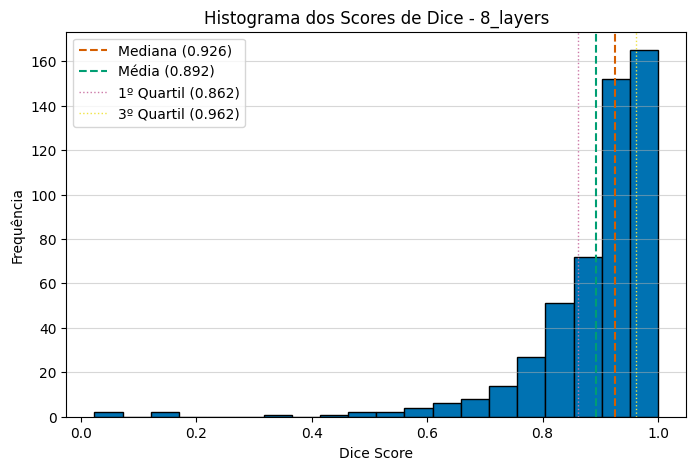

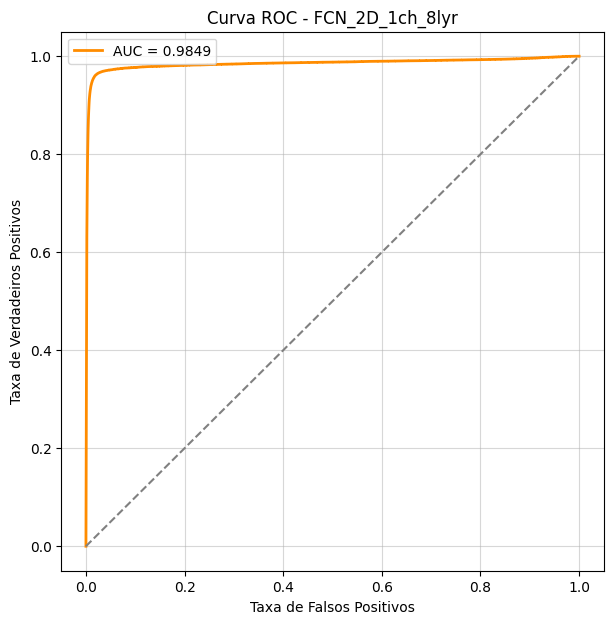


--- Plotando Históricos de Treinamento ---


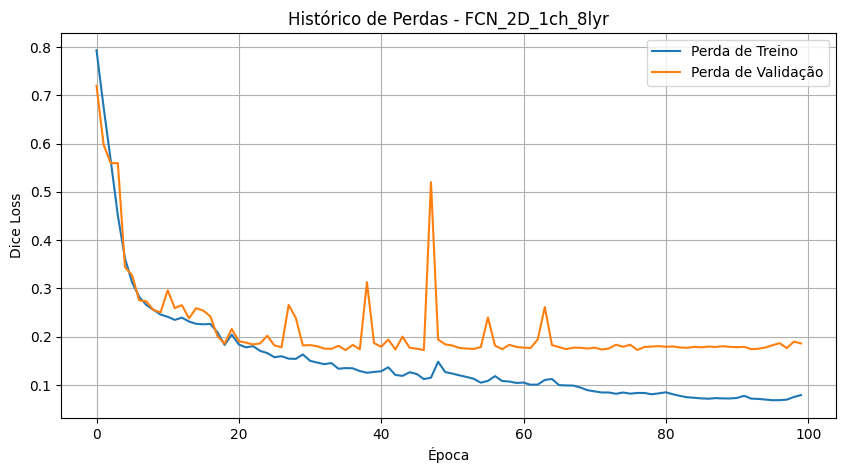

In [68]:

trains = [
    {'channels': 1, 'layers': 8},
]
dices_df = None

for train_config in trains:
    model_name = f'FCN_2D_{train_config["channels"]}ch_{train_config["layers"]}lyr'
    
    dices_dict, labels_flat, preds_flat = calculate_metrics(
        train_config, val_ids, result_path, data_paths
    )
    
    dices_df = save_dices_to_csv(dices_dict, output_path=f'dices_{model_name}.csv')
    
    plot_dice_histogram(dices_df)
    
    labels_np = np.array(labels_flat)
    preds_np = np.array(preds_flat)
    plot_roc_curve(labels_np, preds_np, model_name)


print("\n--- Plotando Históricos de Treinamento ---")
for train_config in trains:
    model_name = f'FCN_2D_{train_config["channels"]}ch_{train_config["layers"]}lyr'
    records_path = os.path.join(result_path, model_name, 'train_record.csv')
    
    if os.path.exists(records_path):
        csv_train = pd.read_csv(records_path)
        plot_training_history(csv_train, model_name)
    else:
        print(f"Aviso: Arquivo de histórico '{records_path}' não encontrado.")

### Visualização dos resultados

In [69]:

best, worst = get_best_worst_ids(dices_df, f'{layers}_layers')

samples = [
    random.choice(best),
    random.choice(best),
    random.choice(worst),
    random.choice(worst)
]

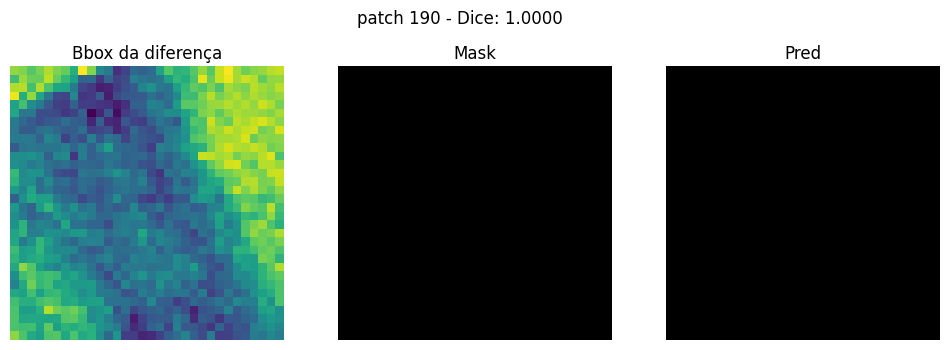

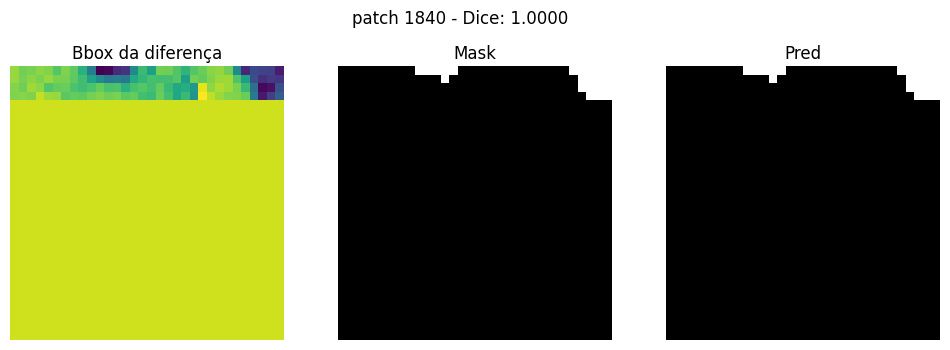

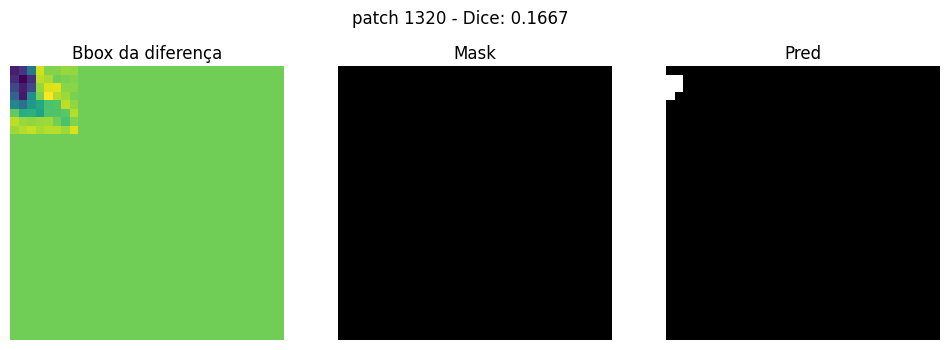

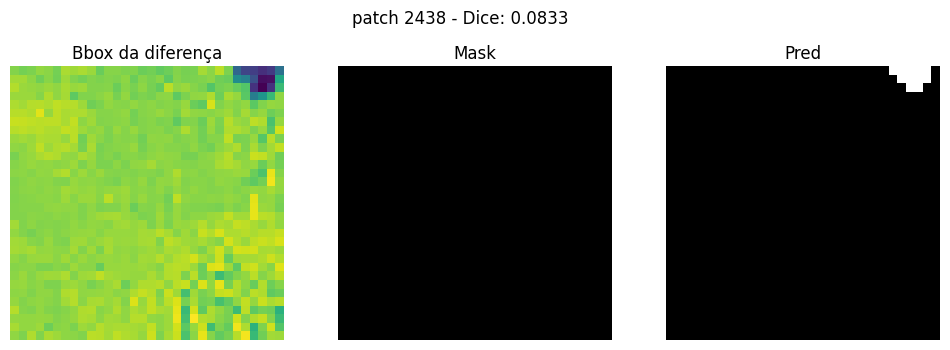

In [70]:


file_path = os.path.join(os.getcwd(), 'results', train_name, 'infer')

for sample in samples:
    mask = read_mask(os.path.join(data_paths['mask'], f'patch_{sample}.tif'))
    pickle_pred = read_pickle(os.path.join(file_path, f'patch_{sample}.pkl'))
    pred_binary = (pickle_pred >= 0.5).astype(np.float32)
    
    diff = read_image(os.path.join(data_paths['diff'], f'patch_{sample}.tif'))
    
    plot_sample(diff, mask, pred_binary[0], f'patch {sample} - Dice: {dices_df[f"{layers}_layers"][sample]:.4f}')

---
# SSD_FCN

## Funções Auxiliares

In [29]:
# Aplicando modelo ssd_fcn em um recorte
def adjust_bbox(xmin, ymin, xmax, ymax, img_height, img_width, min_size=8):
    """
    Ajusta uma bounding box para ser quadrada e ter um tamanho mínimo,
    garantindo que ela não ultrapasse os limites da imagem.
    """
    width = xmax - xmin
    height = ymax - ymin
    max_dim = max(width, height)
    
    center_x = xmin + width / 2
    center_y = ymin + height / 2
    
    new_xmin = int(center_x - max_dim / 2)
    new_ymin = int(center_y - max_dim / 2)
    new_xmax = int(new_xmin + max_dim)
    new_ymax = int(new_ymin + max_dim)

    current_size = new_xmax - new_xmin
    if current_size < min_size:
        new_xmin = int(center_x - min_size / 2)
        new_ymin = int(center_y - min_size / 2)
        new_xmax = int(new_xmin + min_size)
        new_ymax = int(new_ymin + min_size)

    if new_xmin < 0:
        shift = -new_xmin
        new_xmin = 0
        new_xmax += shift
    if new_ymin < 0:
        shift = -new_ymin
        new_ymin = 0
        new_ymax += shift
        
    if new_xmax > img_width:
        shift = new_xmax - img_width
        new_xmax = img_width
        new_xmin -= shift
    if new_ymax > img_height:
        shift = new_ymax - img_height
        new_ymax = img_height
        new_ymin -= shift
        
    if new_xmin < 0: new_xmin = 0
    if new_ymin < 0: new_ymin = 0
    
    return new_xmin, new_ymin, new_xmax, new_ymax

def get_padded_size(size, multiple=32):
    """Calcula o próximo múltiplo de 'multiple' para um dado tamanho."""
    return int(math.ceil(size / multiple)) * multiple

def predict_full_mask_single(basename, model_ssd, model_fcn, 
                      original_folder,
                      mean_ssd, std_ssd, rev_label_map,
                      min_score_ssd=0.15, max_overlap_ssd=0.15, top_k_ssd=20):
    """
    Executa o pipeline completo: detecção com SSD seguida de segmentação com FCN.

    :param basename: (str) O nome do recorte a ser processado.
    :param model_ssd: O objeto do modelo SSD treinado.
    :param model_fcn: O objeto do modelo FCN treinado.
    :param original folder (str): caminho para a pasta que contém a pasta t1 e t2
    :param mean_ssd: (list) Média para normalização do modelo SSD.
    :param std_ssd: (list) Desvio padrão para normalização do modelo SSD.
    :param rev_label_map: (dict) Mapa reverso de rótulos do SSD.
    :param min_score_ssd: (float) Pontuação mínima para detecções do SSD.
    param max_overlap_ssd: (float) Pontuação máxima de sobreposição do SSD
    :param top_k_ssd: (int) Número máximo de detecções do SSD.
    :return: (np.array) A máscara de segmentação binária final do tamanho da imagem original.
    """
    
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model_ssd.eval()
    model_fcn.eval()
    
    t1_folder = os.path.join(original_folder, 't1')
    t2_folder = os.path.join(original_folder, 't2')
    t1_path = os.path.join(t1_folder, basename + '.tif')
    t2_path = os.path.join(t2_folder, basename + '.tif')
    
    if not all(os.path.exists(p) for p in [t1_path, t2_path]):
        print(f"Erro: Arquivos TIF não encontrados para '{basename}'.")
        return None

    with rasterio.open(t1_path) as src: t1_b3, t1_b4 = src.read(3).astype(np.float32), src.read(4).astype(np.float32)
    with rasterio.open(t2_path) as src: t2_b3, t2_b4 = src.read(3).astype(np.float32), src.read(4).astype(np.float32)
    
    img_height, img_width = t1_b3.shape
    idx1 = spyndex.computeIndex(index=["NBRSWIR"], params={"S1": t1_b3, "S2": t1_b4})
    idx2 = spyndex.computeIndex(index=["NBRSWIR"], params={"S1": t2_b3, "S2": t2_b4})
    source_image_float = idx1 - idx2
    
    normalized_8bit = cv2.normalize(source_image_float, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_8U)
    rgb_image_8bit = cv2.cvtColor(normalized_8bit, cv2.COLOR_GRAY2RGB)
    pil_image = Image.fromarray(rgb_image_8bit)
    
    resize_ssd = transforms.Resize((300, 300))
    to_tensor_ssd = transforms.ToTensor()
    normalize_ssd = transforms.Normalize(mean=mean_ssd, std=std_ssd)
    image_for_ssd = normalize_ssd(to_tensor_ssd(resize_ssd(pil_image))).to(device)
    
    with torch.no_grad():
        predicted_locs, predicted_scores = model_ssd(image_for_ssd.unsqueeze(0))
    
    det_boxes_tensor, det_labels_tensor, _ = model_ssd.detect_objects(
        predicted_locs, predicted_scores, min_score=min_score_ssd, max_overlap=max_overlap_ssd, top_k=top_k_ssd
    )
    
    det_boxes = det_boxes_tensor[0].to('cpu')
    det_labels = [rev_label_map[l] for l in det_labels_tensor[0].to('cpu').tolist()]

    if det_labels == ['background']:
        print(f"Nenhuma região de interesse encontrada pelo SSD para '{basename}'.")
        return np.zeros((img_height, img_width), dtype=np.uint8)

    
    original_dims = torch.FloatTensor([pil_image.width, pil_image.height, pil_image.width, pil_image.height]).unsqueeze(0)
    detected_boxes_pixels = (det_boxes * original_dims).tolist()
    
    
    final_mask = np.zeros((img_height, img_width), dtype=np.uint8)
    
    for box in detected_boxes_pixels:
        xmin, ymin, xmax, ymax = int(box[0]), int(box[1]), int(box[2]), int(box[3])
        final_xmin, final_ymin, final_xmax, final_ymax = adjust_bbox(xmin, ymin, xmax, ymax, img_height, img_width, min_size=8)
        
        image_patch = source_image_float[final_ymin:final_ymax, final_xmin:final_xmax]
        h, w = image_patch.shape

        if h <= 32 and w <= 32:
            
            padded_patch = np.zeros((32, 32), dtype=np.float32)
            padded_patch[:h, :w] = image_patch
            
            min_val, max_val = padded_patch.min(), padded_patch.max()
            if max_val - min_val > 0:
                padded_patch = (padded_patch - min_val) / (max_val - min_val)
        
            padded_patch = (padded_patch * 2) - 1
            patch_tensor = torch.from_numpy(padded_patch).float().unsqueeze(0).unsqueeze(0).to(device)
            

            with torch.no_grad():
                pred_mask_32x32_prob = torch.sigmoid(model_fcn(patch_tensor))
            
            mask_padded_np = pred_mask_32x32_prob.squeeze().cpu().numpy()
            reconstructed_mask_prob = mask_padded_np[:h, :w]
            reconstructed_mask = (reconstructed_mask_prob >= 0.5).astype(np.uint8)

        else:
            
            padded_h = get_padded_size(h, 32); padded_w = get_padded_size(w, 32)
            padded_patch = np.zeros((padded_h, padded_w), dtype=np.float32)
            padded_patch[:h, :w] = image_patch
            
            slices = []
            for i in range(0, padded_h, 32):
                for j in range(0, padded_w, 32):
                    slice_np = padded_patch[i:i+32, j:j+32]
                    
                    
                    min_val, max_val = slice_np.min(), slice_np.max()
                    if max_val - min_val > 0:
                        slice_np = (slice_np - min_val) / (max_val - min_val)
                    slice_np = (slice_np * 2) - 1
                    slice_tensor = torch.from_numpy(slice_np).float().unsqueeze(0) 
                    slices.append(slice_tensor)
            
            slices_tensor = torch.stack(slices).to(device)
            
            with torch.no_grad():
                pred_mask_slices_prob = torch.sigmoid(model_fcn(slices_tensor))
                
            reconstructed_padded_mask = np.zeros((padded_h, padded_w), dtype=np.float32)
            slice_idx = 0
            for i in range(0, padded_h, 32):
                for j in range(0, padded_w, 32):
                    reconstructed_padded_mask[i:i+32, j:j+32] = pred_mask_slices_prob[slice_idx].squeeze().cpu().numpy()
                    slice_idx += 1
            
            reconstructed_mask_prob = reconstructed_padded_mask[:h, :w]
            reconstructed_mask = (reconstructed_mask_prob >= 0.5).astype(np.uint8)

    
        current_region = final_mask[final_ymin:final_ymax, final_xmin:final_xmax]
        final_mask[final_ymin:final_ymax, final_xmin:final_xmax] = np.maximum(current_region, reconstructed_mask)

    return final_mask

In [30]:
# Roc for ssd_fcn
def generate_roc_curve(basenames_list, model_ssd, model_fcn, 
                       original_folder,
                       mean_ssd, std_ssd, rev_label_map):
    """
    Executa o modelo híbrido em um conjunto de dados, coleta todas as predições
    e rótulos, e gera a curva ROC com o valor AUC.

    :param basenames_list: (list) Uma lista de strings com os nomes dos recortes a serem avaliados.
    :param model_ssd: O objeto do modelo SSD treinado.
    :param model_fcn: O objeto do modelo FCN treinado.
    :param original_folder: (str) Caminho para a pasta que contém as subpastas t1, t2 e mask.
    
    """
    
    all_true_pixels = []
    all_pred_probs = []
    
    print(f"Gerando predições para {len(basenames_list)} imagens para a curva ROC...")
    
    
    for basename in tqdm(basenames_list, desc="Avaliando imagens"):
       
        predicted_prob_map = predict_full_mask_single(
            basename, model_ssd, model_fcn, 
            original_folder, 
            mean_ssd, std_ssd, rev_label_map
        )
        
        if predicted_prob_map is None:
            continue

        
        mask_path = os.path.join(original_folder, 'mask', basename + '.tif')
        with rasterio.open(mask_path) as src:
            true_mask = src.read(1)
            true_mask = (true_mask > 0).astype(np.uint8)
            
       
        all_true_pixels.extend(true_mask.ravel())
        all_pred_probs.extend(predicted_prob_map.ravel())

    if not all_true_pixels:
        print("Nenhum dado foi coletado. Verifique os caminhos e o dataset.")
        return

    print("\nCalculando as métricas da curva ROC...")
    
   
    y_true = np.array(all_true_pixels)
    y_scores = np.array(all_pred_probs)
    
    
    auc = roc_auc_score(y_true, y_scores)
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)

    print(f"AUC-ROC Calculado: {auc:.4f}")

    
    plt.figure(figsize=(8, 8))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f"AUC = {auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--", color="navy", lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("Taxa de Falsos Positivos (FPR)", fontsize=12)
    plt.ylabel("Taxa de Verdadeiros Positivos (TPR)", fontsize=12)
    plt.title("Curva ROC do Modelo Híbrido", fontsize=14)
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

In [43]:
# Aplicar na validação
def adjust_bbox(xmin, ymin, xmax, ymax, img_height, img_width, min_size=8):
    width = xmax - xmin; height = ymax - ymin
    max_dim = max(width, height)
    center_x = xmin + width / 2; center_y = ymin + height / 2
    new_xmin = int(center_x - max_dim / 2); new_ymin = int(center_y - max_dim / 2)
    new_xmax = int(new_xmin + max_dim); new_ymax = int(new_ymin + max_dim)
    current_size = new_xmax - new_xmin
    if current_size < min_size:
        new_dim = min_size
        new_xmin = int(center_x - new_dim / 2); new_ymin = int(center_y - new_dim / 2)
        new_xmax = int(new_xmin + new_dim); new_ymax = int(new_ymin + new_dim)
    if new_xmin < 0:
        shift = -new_xmin; new_xmin = 0; new_xmax += shift
    if new_ymin < 0:
        shift = -new_ymin; new_ymin = 0; new_ymax += shift
    if new_xmax > img_width:
        shift = new_xmax - img_width; new_xmax = img_width; new_xmin -= shift
    if new_ymax > img_height:
        shift = new_ymax - img_height; new_ymax = img_height; new_ymin -= shift
    if new_xmin < 0: new_xmin = 0
    if new_ymin < 0: new_ymin = 0
    return new_xmin, new_ymin, new_xmax, new_ymax

def get_padded_size(size, multiple=32):
    return int(math.ceil(size / multiple)) * multiple



def predict_final_mask(basename, model_ssd, model_fcn, original_folder,
                       mean_ssd, std_ssd, rev_label_map, min_score=0.15, max_overlap=0.15, top_k=20):
    """
    Função interna que executa o pipeline completo para UM recorte e retorna a
    máscara binária final. Usa a preparação manual de patches para a FCN.
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model_ssd.eval(); model_fcn.eval()
    
    t1_folder = os.path.join(original_folder, 't1'); t2_folder = os.path.join(original_folder, 't2')
    t1_path = os.path.join(t1_folder, basename + '.tif'); t2_path = os.path.join(t2_folder, basename + '.tif')
    if not all(os.path.exists(p) for p in [t1_path, t2_path]): return None
    with rasterio.open(t1_path) as src: t1_b3, t1_b4 = src.read(3).astype(np.float32), src.read(4).astype(np.float32)
    with rasterio.open(t2_path) as src: t2_b3, t2_b4 = src.read(3).astype(np.float32), src.read(4).astype(np.float32)
    img_height, img_width = t1_b3.shape
    idx1 = spyndex.computeIndex(index=["NBRSWIR"], params={"S1": t1_b3, "S2": t1_b4})
    idx2 = spyndex.computeIndex(index=["NBRSWIR"], params={"S1": t2_b3, "S2": t2_b4})
    source_image_float = idx1 - idx2
    normalized_8bit = cv2.normalize(source_image_float, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_8U)
    pil_image = Image.fromarray(cv2.cvtColor(normalized_8bit, cv2.COLOR_GRAY2RGB))
    
    resize_ssd = transforms.Resize((300, 300)); to_tensor_ssd = transforms.ToTensor()
    normalize_ssd = transforms.Normalize(mean=mean_ssd, std=std_ssd)
    image_for_ssd = normalize_ssd(to_tensor_ssd(resize_ssd(pil_image))).to(device)
    
    with torch.no_grad():
        predicted_locs, predicted_scores = model_ssd(image_for_ssd.unsqueeze(0))
    det_boxes_tensor, det_labels_tensor, _ = model_ssd.detect_objects(predicted_locs, predicted_scores, min_score=min_score, max_overlap=max_overlap, top_k=top_k)
    det_boxes = det_boxes_tensor[0].to('cpu'); det_labels = [rev_label_map[l] for l in det_labels_tensor[0].to('cpu').tolist()]
    
    if det_labels == ['background']:
        return np.zeros((img_height, img_width), dtype=np.uint8)

    original_dims = torch.FloatTensor([pil_image.width, pil_image.height, pil_image.width, pil_image.height]).unsqueeze(0)
    detected_boxes_pixels = (det_boxes * original_dims).tolist()
    
    final_mask = np.zeros((img_height, img_width), dtype=np.uint8)
    
    for box in detected_boxes_pixels:
        xmin, ymin, xmax, ymax = int(box[0]), int(box[1]), int(box[2]), int(box[3])
        final_xmin, final_ymin, final_xmax, final_ymax = adjust_bbox(xmin, ymin, xmax, ymax, img_height, img_width, min_size=8)
        
        image_patch = source_image_float[final_ymin:final_ymax, final_xmin:final_xmax]
        h, w = image_patch.shape

        if h > 0 and w > 0:
            
            if h <= 32 and w <= 32:
                padded_patch = np.zeros((32, 32), dtype=np.float32); padded_patch[:h, :w] = image_patch
                min_val, max_val = padded_patch.min(), padded_patch.max()
                if max_val - min_val > 0: padded_patch = (padded_patch - min_val) / (max_val - min_val)
                padded_patch = (padded_patch * 2) - 1
                patch_tensor = torch.from_numpy(padded_patch).float().unsqueeze(0).unsqueeze(0).to(device)
                with torch.no_grad(): pred_mask_32x32_prob = torch.sigmoid(model_fcn(patch_tensor))
                mask_padded_np = pred_mask_32x32_prob.squeeze().cpu().numpy()
                reconstructed_mask_prob = mask_padded_np[:h, :w]
                reconstructed_mask = (reconstructed_mask_prob >= 0.5).astype(np.uint8)
            else:
                padded_h = get_padded_size(h, 32); padded_w = get_padded_size(w, 32)
                padded_patch = np.zeros((padded_h, padded_w), dtype=np.float32); padded_patch[:h, :w] = image_patch
                slices = []
                for i in range(0, padded_h, 32):
                    for j in range(0, padded_w, 32):
                        slice_np = padded_patch[i:i+32, j:j+32]
                        min_val, max_val = slice_np.min(), slice_np.max()
                        if max_val - min_val > 0: slice_np = (slice_np - min_val) / (max_val - min_val)
                        slice_np = (slice_np * 2) - 1
                        slices.append(torch.from_numpy(slice_np).float().unsqueeze(0))
                slices_tensor = torch.stack(slices).to(device)
                with torch.no_grad(): pred_mask_slices_prob = torch.sigmoid(model_fcn(slices_tensor))
                reconstructed_padded_mask = np.zeros((padded_h, padded_w), dtype=np.float32)
                slice_idx = 0
                for i in range(0, padded_h, 32):
                    for j in range(0, padded_w, 32):
                        reconstructed_padded_mask[i:i+32, j:j+32] = pred_mask_slices_prob[slice_idx].squeeze().cpu().numpy()
                        slice_idx += 1
                reconstructed_mask_prob = reconstructed_padded_mask[:h, :w]
                reconstructed_mask = (reconstructed_mask_prob >= 0.5).astype(np.uint8)

            current_region = final_mask[final_ymin:final_ymax, final_xmin:final_xmax]
            final_mask[final_ymin:final_ymax, final_xmin:final_xmax] = np.maximum(current_region, reconstructed_mask)

    return final_mask


def generate_submission_csv(model_ssd, model_fcn, eval_folder, 
                            mean_ssd, std_ssd, rev_label_map, 
                            output_csv_path='predicted_change_masks.csv', min_score=0.15, max_overlap=0.15, top_k=20):
    """
    Orquestra a predição em todo o dataset de avaliação e salva os
    resultados em um arquivo CSV para submissão.
    """
    t1_folder = os.path.join(eval_folder, 't1')
    
    
    basenames = [os.path.splitext(f)[0] for f in os.listdir(t1_folder) if f.endswith('.tif')]
    
    print(f"Encontrados {len(basenames)} recortes para gerar a submissão.")

    with open(output_csv_path, "w", newline="") as f:
        writer = csv.writer(f)

        
        with rasterio.open(os.path.join(t1_folder, basenames[0] + '.tif')) as src:
            num_pixels = src.height * src.width
        
        header = ["id"] + [f"pixel_{i}" for i in range(num_pixels)]
        writer.writerow(header)

        
        for basename in tqdm(basenames, desc="Gerando predições"):
            
            final_binary_mask = predict_final_mask(
                basename, model_ssd, model_fcn, 
                eval_folder, mean_ssd, std_ssd, rev_label_map,
                min_score=min_score, max_overlap=max_overlap, top_k=top_k
            )
            
            if final_binary_mask is not None:
                
                flattened_mask = final_binary_mask.flatten().tolist()
                row = [basename+'.tif'] + flattened_mask
                writer.writerow(row)

    print(f"\n✅ Arquivo de submissão '{output_csv_path}' gerado com sucesso!")

In [32]:
# Modularização


def load_models(ssd_checkpoint_path, fcn_checkpoint_path, device, channels, layers):
    """
    Carrega os modelos SSD e FCN treinados a partir de seus checkpoints.

    :param ssd_checkpoint_path: (str) Caminho para o arquivo .pth.tar do modelo SSD.
    :param fcn_checkpoint_path: (str) Caminho para o arquivo .pkl do modelo FCN.
    :param device: (torch.device) O dispositivo para alocar os modelos.
    :param channels: (int) Número de canais de entrada para o modelo FCN.
    :param layers: (int) Número de camadas/features para o modelo FCN.
    :return: (tuple) Uma tupla contendo os modelos carregados (model_ssd, model_fcn).
    """
    print("Carregando modelo SSD...")
    checkpoint_ssd = torch.load(ssd_checkpoint_path, weights_only=False)
    model_ssd = checkpoint_ssd['model'].to(device)
    model_ssd.eval()
    print("Modelo SSD carregado.")

    print(f"Carregando modelo FCN de '{fcn_checkpoint_path}'...")
    model_fcn = FCN_2D(channels, layers).to(device)
    model_fcn.load_state_dict(torch.load(fcn_checkpoint_path))
    model_fcn.eval()
    print("Modelo FCN carregado.")
    
    return model_ssd, model_fcn



def plot_comparison(basename, predicted_mask, original_data_folder):
    """
    Plota a imagem de entrada, a máscara prevista e a máscara de referência.

    :param basename: (str) O nome do recorte a ser visualizado.
    :param predicted_mask: (np.array) A máscara binária final gerada pelo modelo.
    :param original_data_folder: (str) O caminho para a pasta com os dados originais (t1, t2, mask).
    :return: None
    """
    if predicted_mask is None:
        print("Máscara prevista é Nula. Abortando a plotagem.")
        return
        
    # Gera a imagem de entrada original para visualização
    t1_path = os.path.join(original_data_folder, 't1', basename + '.tif')
    t2_path = os.path.join(original_data_folder, 't2', basename + '.tif')
    mask_path = os.path.join(original_data_folder, 'mask', basename + '.tif')

    with rasterio.open(t1_path) as src: t1_b3, t1_b4 = src.read(3).astype(np.float32), src.read(4).astype(np.float32)
    with rasterio.open(t2_path) as src: t2_b3, t2_b4 = src.read(3).astype(np.float32), src.read(4).astype(np.float32)
    with rasterio.open(mask_path) as src: ground_truth_mask = src.read(1)
        
    idx1 = spyndex.computeIndex(index=["NBRSWIR"], params={"S1": t1_b3, "S2": t1_b4})
    idx2 = spyndex.computeIndex(index=["NBRSWIR"], params={"S1": t2_b3, "S2": t2_b4})
    img_np = idx1 - idx2
    input_image_display = cv2.normalize(img_np, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_8U)
    
    ground_truth_mask_display = cv2.normalize(ground_truth_mask, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_8U)

    # Plotagem
    plt.figure(figsize=(18, 6))
    
    plt.subplot(1, 3, 1)
    plt.imshow(input_image_display, cmap='gray')
    plt.title(f'Imagem de Entrada ({basename})')
    plt.axis('off')
    
    plt.subplot(1, 3, 2)
    plt.imshow(predicted_mask, cmap='gray')
    plt.title('Máscara Final Prevista')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(ground_truth_mask_display, cmap='gray')
    plt.title('Máscara Original')
    plt.axis('off')
    
    plt.show()

## Fluxo Principal


### Parâmetros e Variáveis


In [33]:

ssd_checkpoint_path = 'checkpoint_diff.pth.tar'
fcn_result_path = './results' 
fcn_channels = 1
fcn_layers = 8
fcn_load_epoch = 45

data_original_path = './dataset_kaggle/dataset'

mean_ssd, std_ssd = mean_Diff, std_Diff 
rev_label_map = {1: 'burn_scar', 0: 'background'} 

### Aplicando o modelo SDD_FCN em uma imagem e comparando resultado

Carregando modelo SSD...
Modelo SSD carregado.
Carregando modelo FCN de './results/FCN_2D_1ch_8lyr/net_45.pkl'...
Modelo FCN carregado.


/tmp/ipykernel_4117/758936025.py:493: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at /pytorch/aten/src/ATen/native/IndexingUtils.h:29.)
  image_boxes.append(class_decoded_locs[1 - suppress])
/tmp/ipykernel_4117/758936025.py:495: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at /pytorch/aten/src/ATen/native/IndexingUtils.h:29.)
  image_scores.append(class_scores[1 - suppress])


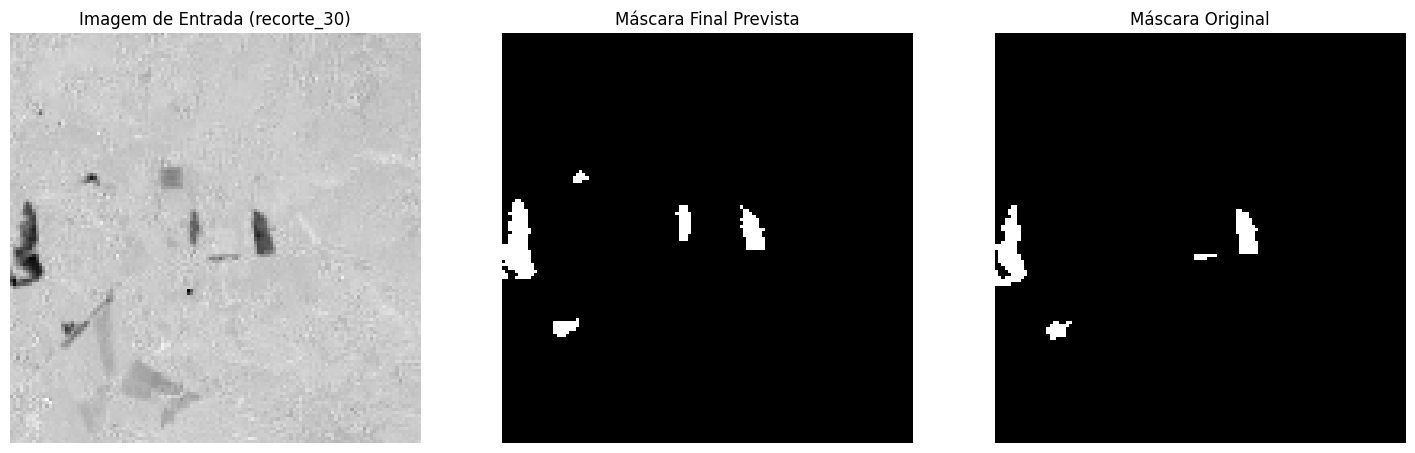

In [49]:

basename_para_prever = 'recorte_30'

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

fcn_model_path = os.path.join(fcn_result_path, 
                              f'FCN_2D_{fcn_channels}ch_{fcn_layers}lyr', 
                              f'net_{fcn_load_epoch}.pkl')

model_ssd, model_fcn = load_models(ssd_checkpoint_path, fcn_model_path, 
                                   device, fcn_channels, fcn_layers)

mascara_final_predita = predict_full_mask_single(
    basename_para_prever, 
    model_ssd, 
    model_fcn, 
    data_original_path, 
    mean_ssd, 
    std_ssd, 
    rev_label_map,
    min_score_ssd=0.15
)

plot_comparison(basename_para_prever, mascara_final_predita, data_original_path)

### Gerando Curva Roc com o modelo ssd_fcn

Encontradas 59 imagens no conjunto de teste.
Gerando predições para 59 imagens para a curva ROC...


Avaliando imagens:   0%|          | 0/59 [00:00<?, ?it/s]/tmp/ipykernel_1361/758936025.py:493: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at /pytorch/aten/src/ATen/native/IndexingUtils.h:29.)
  image_boxes.append(class_decoded_locs[1 - suppress])
/tmp/ipykernel_1361/758936025.py:495: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at /pytorch/aten/src/ATen/native/IndexingUtils.h:29.)
  image_scores.append(class_scores[1 - suppress])
Avaliando imagens: 100%|██████████| 59/59 [00:11<00:00,  5.18it/s]



Calculando as métricas da curva ROC...
AUC-ROC Calculado: 0.9459


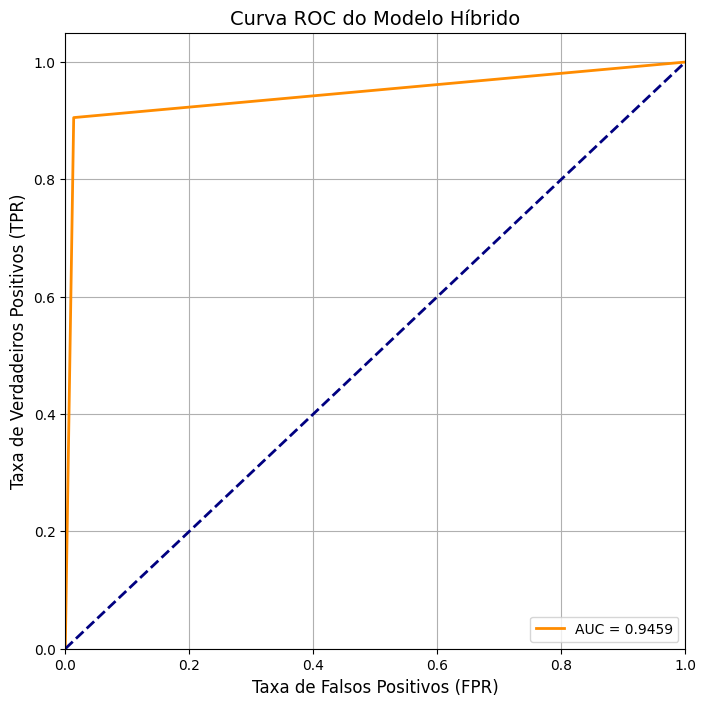

In [83]:

test_set_path = './BurnScarDataset_SSD/ImageSets/Main/test.txt'
with open(test_set_path, 'r') as f:
    test_basenames = [line.strip() for line in f.readlines()]

print(f"Encontradas {len(test_basenames)} imagens no conjunto de teste.")


generate_roc_curve(
    basenames_list=test_basenames,
    model_ssd=model_ssd,
    model_fcn=model_fcn,
    original_folder=data_original,
    mean_ssd=mean_Diff,
    std_ssd=std_Diff,
    rev_label_map=rev_label_map
)

### Gerando csv

In [ ]:
evaluation_folder_path = './dataset_kaggle/avaliacao' 

generate_submission_csv(
     model_ssd=model_ssd,
     model_fcn=model_fcn,
     eval_folder=evaluation_folder_path,
     mean_ssd=mean_Diff,
     std_ssd=std_Diff,
     rev_label_map=rev_label_map,
     min_score=0.15, max_overlap=0.15, top_k=20
)

Encontrados 315 recortes para gerar a submissão.


Gerando predições:   0%|          | 0/315 [00:00<?, ?it/s]/tmp/ipykernel_4117/758936025.py:493: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at /pytorch/aten/src/ATen/native/IndexingUtils.h:29.)
  image_boxes.append(class_decoded_locs[1 - suppress])
/tmp/ipykernel_4117/758936025.py:495: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at /pytorch/aten/src/ATen/native/IndexingUtils.h:29.)
  image_scores.append(class_scores[1 - suppress])
Gerando predições: 100%|██████████| 315/315 [05:09<00:00,  1.02it/s]


✅ Arquivo de submissão 'predicted_change_masks.csv' gerado com sucesso!


In [46]:
submission_df = pd.read_csv('predicted_change_masks.csv')
print(submission_df.head())

                id  pixel_0  pixel_1  pixel_2  pixel_3  pixel_4  pixel_5  \
0    recorte_1.tif        0        0        0        0        0        0   
1   recorte_10.tif        0        0        0        0        0        0   
2  recorte_100.tif        0        0        0        0        0        0   
3  recorte_101.tif        0        0        0        0        0        0   
4  recorte_102.tif        0        0        0        0        0        0   

   pixel_6  pixel_7  pixel_8  ...  pixel_16374  pixel_16375  pixel_16376  \
0        0        0        0  ...            0            0            0   
1        0        0        0  ...            0            0            0   
2        0        0        0  ...            0            0            0   
3        0        0        0  ...            0            0            0   
4        0        0        0  ...            0            0            0   

   pixel_16377  pixel_16378  pixel_16379  pixel_16380  pixel_16381  \
0            0  